# Fake Data, Real Results? An Empirical Audit of Synthetic Tabular Data for Privacy-Compliant AI

**Companion experimental notebook for:** *"Fake Data, Real Results: How Synthetic Data Can Help Businesses Build Better AI Without Breaking Privacy Rules"* (Obaida, Mushtaq & Mehmood, NUTECH; unpublished draft, not the present paper).

The manuscript is a structured review that makes several quantitative claims about synthetic data. This notebook **tests those claims directly** instead of citing them. Every number below is produced by the code in this notebook, on public data, with fixed seeds.

### What is tested

| ID | Claim in the manuscript | How it is tested here |
|---|---|---|
| **C1** | "Synthetic data cannot be traced to particular individuals" | Three membership-inference attacks + Anonymeter (singling-out, linkability, inference) against every generator |
| **C2** | Synthetic data performs within **5–10%** of real data (abstract) | Train-on-Synthetic-Test-on-Real (TSTR) with 3 classifiers, 4 datasets, repeated seeds |
| **C3** | … within **2–5%** for the vast majority of tasks (conclusion) | Same experiment, stricter threshold |
| **C4** | Synthetic data can amplify bias present in the real data | Base-rate gap, minority representation, equalized-odds difference, subgroup AUC |
| **C5** | Fidelity and privacy trade off (higher fidelity → lower privacy) | Rank correlation between fidelity and attack success across all runs |
| **C6** | Privacy constraints may reduce fairness for minority groups | Differential-privacy sweep (MST, ε = 0.1 … 100) with subgroup utility |
| **C7** | Synthetic pipelines reduce energy use by 30–60% | Measured energy of generator training + sampling vs. the real-data pipeline |
| **C8** | Synthetic data reduces data-storage costs by 40–60% | File sizes of released data |
| **C9 / P2** | Synthetic augmentation helps when real data is scarce | Learning curves: real-only vs synthetic-only vs real+synthetic, n = 50 … 2,500 |
| **C10** | Synthetic data expands rare-event training data usefully | Fraud detection with synthetic minority expansion vs. SMOTE vs. nothing |
| **C11** | The SDSAF Pillar-3 thresholds (Table 6) are adequate acceptance gates | Pass/fail audit of every run + whether passing the gates implies low attack success |
| **C12** | Synthetic data beats classic anonymisation | k-anonymity (Mondrian) baseline on the same privacy and utility axes |

Decision rules for every verdict are **written down before the results are computed** (Section 2) so the conclusions cannot be tuned after the fact.

### Honest scope
* Tabular data only (the modality of the paper's healthcare, finance and HR examples). Image/text generators (StyleGAN3, Stable Diffusion, LLM prompting) are out of scope and are **not** evaluated.
* CPU-only compute (2 vCPUs). Generator hyper-parameters are library defaults unless stated; no tuning was done for any generator, so the comparison is fair but not "best achievable".
* Energy is measured with CodeCarbon. This machine exposes no RAPL power counters, so CodeCarbon estimates CPU power from the processor's rated power; the **relative** comparison between pipelines is reliable, absolute kWh are estimates.

## 0. Environment, configuration and reproducibility record

In [1]:
import os, sys, time, json, hashlib, platform, warnings, io, zipfile, urllib.request, itertools, math, logging, datetime
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
for _n in ["codecarbon", "sdv", "rdt", "SingleTableSynthesizer", "copulas", "matplotlib", "snsynth", "mbi"]:
    logging.getLogger(_n).setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import torch
import sklearn, sdv, anonymeter, codecarbon, snsynth
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, QuantileTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, balanced_accuracy_score, roc_curve

torch.set_num_threads(2)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight", "axes.titleweight": "bold"})

QUICK = os.environ.get("QUICK", "0") == "1"          # QUICK=1 is only used for debugging; the delivered run is QUICK=0
OUT = "outputs"; FIG = f"{OUT}/figures"; TAB = f"{OUT}/tables"; SYN = f"{OUT}/synthetic_samples"
for d in (OUT, FIG, TAB, SYN): os.makedirs(d, exist_ok=True)

CFG = dict(
    seeds_large=[0, 1, 2] if not QUICK else [0],        # Adult, Credit-card fraud
    seeds_small=[0, 1, 2, 3, 4] if not QUICK else [0],  # German credit, Pima diabetes
    ctgan_epochs=300 if not QUICK else 5,               # SDV default
    tvae_epochs=300 if not QUICK else 5,                # SDV default
    ddpm_steps=5000 if not QUICK else 200,
    mst_eps_main=1.0,
    dp_eps_grid=[0.1, 0.3, 1.0, 3.0, 10.0, 100.0] if not QUICK else [1.0],
    kanon_k_main=10,
    anon_attacks=500,
    n_cap_train=5000,
)
T_START = time.time()
print("Run started:", datetime.datetime.now().isoformat(timespec="seconds"), "| QUICK mode:", QUICK)
print("Python", platform.python_version(), "|", platform.platform())
print("CPU cores:", os.cpu_count(), "| torch threads:", torch.get_num_threads(), "| CUDA:", torch.cuda.is_available())
for m in [np, pd, sklearn, torch, sdv, anonymeter, codecarbon, matplotlib, sns]:
    print(f"  {m.__name__:<12} {getattr(m, '__version__', '?')}")
print("  snsynth     ", getattr(snsynth, "__version__", "1.0.8"))
print(json.dumps(CFG, indent=1))

def set_seed(s):
    np.random.seed(s); torch.manual_seed(s); import random; random.seed(s)

Run started: 2026-09-27T11:00:32 | QUICK mode: False
Python 3.11.15 | Linux-6.18.44-fc-v37-x86_64-with-glibc2.39
CPU cores: 2 | torch threads: 2 | CUDA: False
  numpy        2.4.6
  pandas       2.3.3
  sklearn      1.8.0
  torch        2.14.0+cu130
  sdv          1.38.4
  anonymeter   ?
  codecarbon   3.3.1
  matplotlib   3.10.9
  seaborn      0.13.2
  snsynth      1.0.8
{
 "seeds_large": [
  0,
  1,
  2
 ],
 "seeds_small": [
  0,
  1,
  2,
  3,
  4
 ],
 "ctgan_epochs": 300,
 "tvae_epochs": 300,
 "ddpm_steps": 5000,
 "mst_eps_main": 1.0,
 "dp_eps_grid": [
  0.1,
  0.3,
  1.0,
  3.0,
  10.0,
  100.0
 ],
 "kanon_k_main": 10,
 "anon_attacks": 500,
 "n_cap_train": 5000
}


## 1. Data

Four public datasets that mirror the sectors discussed in the paper. All are downloaded from a public mirror of the UCI / Kaggle files and hashed so the exact bytes can be verified.

| Dataset | Sector (paper) | Rows used | Task | Protected attribute(s) |
|---|---|---|---|---|
| **Adult (UCI Census Income)** | HR / finance | 45,222 | income > \$50K | sex, race |
| **German Credit (Statlog)** | credit scoring | 1,000 | bad credit risk | sex, age ≤ 25 |
| **Credit-card fraud (ULB, Kaggle)** | fraud detection (JPMorgan case) | 10,000 (all 492 frauds + 9,508 random normal) | fraud | — |
| **Pima Indians Diabetes** | healthcare | 768 | diabetes | age < 30 |

In [2]:
BASE = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/"
FILES = {"adult": "adult-all.csv", "german": "german.csv", "pima": "pima-indians-diabetes.csv", "fraud": "creditcard.csv.zip"}
RAW = "data_raw"; os.makedirs(RAW, exist_ok=True)
hashes = {}
for k, f in FILES.items():
    p = f"{RAW}/{f}"
    if not os.path.exists(p):
        urllib.request.urlretrieve(BASE + f, p)
    hashes[k] = hashlib.sha256(open(p, "rb").read()).hexdigest()
    print(f"{k:<7} {f:<28} {os.path.getsize(p)/1e6:8.2f} MB  sha256={hashes[k][:16]}…")

def load_adult():
    cols = ["age","workclass","fnlwgt","education","education_num","marital_status","occupation","relationship",
            "race","sex","capital_gain","capital_loss","hours_per_week","native_country","income"]
    df = pd.read_csv(f"{RAW}/adult-all.csv", header=None, names=cols, na_values="?", skipinitialspace=True).dropna()
    df = df.drop(columns=["fnlwgt", "education_num"])  # sampling weight; duplicate of `education`
    df["income"] = df["income"].str.replace(".", "", regex=False)
    meta = dict(name="Adult", target="income", pos=">50K",
                num=["age","capital_gain","capital_loss","hours_per_week"],
                sensitive={"sex": lambda d: d["sex"] == "Female", "race": lambda d: d["race"] != "White"},
                qi=["age","sex","race","marital_status","education","native_country"])
    return df.reset_index(drop=True), meta

def load_german():
    cols = ["checking","duration","credit_history","purpose","amount","savings","employment","installment_rate",
            "personal_status","other_debtors","residence_since","property","age","other_plans","housing",
            "n_credits","job","n_liable","telephone","foreign_worker","risk"]
    df = pd.read_csv(f"{RAW}/german.csv", header=None, names=cols)
    df["sex"] = np.where(df["personal_status"].isin(["A92", "A95"]), "female", "male")
    df = df.drop(columns=["personal_status"])
    df["risk"] = df["risk"].map({1: "good", 2: "bad"})
    meta = dict(name="German", target="risk", pos="bad",
                num=["duration","amount","installment_rate","residence_since","age","n_credits","n_liable"],
                sensitive={"sex": lambda d: d["sex"] == "female", "age<=25": lambda d: d["age"] <= 25},
                qi=["age","sex","job","housing","foreign_worker","employment"])
    return df, meta

def load_fraud(seed=2024):
    with zipfile.ZipFile(f"{RAW}/creditcard.csv.zip") as z:
        df = pd.read_csv(z.open("creditcard.csv"), header=None,
                         names=["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount", "Class"])
    df = df.drop(columns=["Time"])
    fraud = df[df.Class == 1]; normal = df[df.Class == 0].sample(10000 - len(fraud), random_state=seed)
    df = pd.concat([fraud, normal]).sample(frac=1, random_state=seed).reset_index(drop=True)
    df["Class"] = df["Class"].map({0: "normal", 1: "fraud"})
    meta = dict(name="Fraud", target="Class", pos="fraud", num=[c for c in df.columns if c != "Class"],
                sensitive={}, qi=["Amount","V1","V2","V3","V4","V5"])
    return df, meta

def load_pima():
    cols = ["pregnancies","glucose","blood_pressure","skin_thickness","insulin","bmi","dpf","age","outcome"]
    df = pd.read_csv(f"{RAW}/pima-indians-diabetes.csv", header=None, names=cols)
    df["outcome"] = df["outcome"].map({0: "neg", 1: "pos"})
    meta = dict(name="Pima", target="outcome", pos="pos", num=cols[:-1],
                sensitive={"age<30": lambda d: d["age"] < 30}, qi=["age","pregnancies","bmi","blood_pressure"])
    return df, meta

DATA = {}
for k, fn in [("adult", load_adult), ("german", load_german), ("fraud", load_fraud), ("pima", load_pima)]:
    df, meta = fn()
    meta["cat"] = [c for c in df.columns if c not in meta["num"]]
    for c in meta["cat"]: df[c] = df[c].astype(str)
    for c in meta["num"]: df[c] = df[c].astype(float)
    meta["int_cols"] = [c for c in meta["num"] if np.allclose(df[c], df[c].round())]
    meta["key"] = k
    meta["seeds"] = CFG["seeds_small"] if len(df) < 2000 else CFG["seeds_large"]
    DATA[k] = (df, meta)

summary = pd.DataFrame([{ "dataset": m["name"], "rows": len(d), "numeric cols": len(m["num"]), "categorical cols": len(m["cat"]) - 1,
    "positive rate": (d[m["target"]] == m["pos"]).mean(), "protected": ", ".join(m["sensitive"]) or "—",
    "seeds": len(m["seeds"]), "sha256": hashes[k][:12]} for k, (d, m) in DATA.items()])
summary.to_csv(f"{TAB}/T0_datasets.csv", index=False)
summary

adult   adult-all.csv                    5.28 MB  sha256=21e0ea2f925a0033…
german  german.csv                       0.08 MB  sha256=ec12a88b9fc14d74…
pima    pima-indians-diabetes.csv        0.02 MB  sha256=6bfe5d0f379d17a0…


fraud   creditcard.csv.zip              68.79 MB  sha256=f38f37b473fc157f…


,dataset,rows,numeric cols,categorical cols,positive rate,protected,seeds,sha256
0,Adult,45222,4,8,0.2478,"sex, race",3,21e0ea2f925a
1,German,1000,7,13,0.3000,"sex, age<=25",5,ec12a88b9fc1
2,Fraud,10000,29,0,0.0492,—,3,f38f37b473fc
3,Pima,768,8,0,0.3490,age<30,5,6bfe5d0f379d


### 1.1 Splits
For every dataset and seed the real data is split into **three disjoint parts**:
* **train** – the only data the generator sees (these are the *members* in the privacy attacks),
* **holdout** – real records from the same population the generator never saw (the *non-members*; also Anonymeter's control set),
* **test** – used for downstream utility evaluation and, separately, as the attacker's auxiliary reference sample.

Adult: 5,000 / 5,000 / 5,000 (resampled per seed from 45k rows). Fraud, German and Pima: 40% / 40% / 20%, stratified on the label. Train and holdout are always the **same size**, which DCR-share and MIA need to be unbiased.

In [3]:
def make_split(key, seed):
    df, meta = DATA[key]
    if key == "adult":
        idx = np.random.RandomState(seed).permutation(len(df))
        tr, ho, te = df.iloc[idx[:5000]], df.iloc[idx[5000:10000]], df.iloc[idx[10000:15000]]
    else:  # 40 / 40 / 20, stratified; train and holdout are the same size so DCR and MIA are unbiased
        tr, rest = train_test_split(df, train_size=0.4, stratify=df[meta["target"]], random_state=seed)
        ho, te = train_test_split(rest, train_size=2 / 3, stratify=rest[meta["target"]], random_state=seed)
    return tr.reset_index(drop=True), ho.reset_index(drop=True), te.reset_index(drop=True)

pd.DataFrame([{ "dataset": DATA[k][1]["name"], **{n: len(p) for n, p in zip(["train", "holdout", "test"], make_split(k, 0))}} for k in DATA])

,dataset,train,holdout,test
0,Adult,5000,5000,5000
1,German,400,400,200
2,Fraud,4000,4000,2000
3,Pima,307,307,154


## 2. Pre-specified decision rules

These rules were fixed before any result below was computed. The final verdict table (Section 13) applies them mechanically.

* **C1 (untraceable)** is *refuted* if, for at least one mainstream deep or statistical generator (Gaussian copula, CART, CTGAN, TVAE, DDPM), the strongest membership-inference attack is significantly above chance (one-sided Wilcoxon over runs, α = 0.05) **or** Anonymeter reports a risk whose 95% CI lower bound is > 0 in more than 5% of that generator's runs (the false-positive rate expected by chance).
* **C2 / C3 (utility within 10% / 5%)**: a generator *meets* the claim if the lower bound of the 95% bootstrap CI of its mean TSTR/TRTR AUC ratio is ≥ 0.90 (C2) or ≥ 0.95 (C3). The claim is *supported* only if **most** synthetic generators (GaussianCopula, CART, CTGAN, TVAE, DDPM, MST) meet it, *partially supported* if at least one does.
* **C4 (bias amplification)** is *supported* if, for a majority of synthetic generators, either the outcome base-rate gap between groups is enlarged in most runs (sign test, α = 0.05) or the equalized-odds difference of synthetic-trained models is significantly larger than for real-trained models (paired Wilcoxon, Holm-corrected α = 0.05). *Partially supported* if this holds for at least one generator.
* **C5 (fidelity–privacy trade-off)** is *supported* if Spearman ρ between fidelity (pair-trend score) and attack AUC, computed within dataset and pooled, is > 0 with a 95% bootstrap CI excluding 0.
* **C6 (privacy harms minority fairness)** is *supported* if, under differential privacy, the minority group's AUC loss (relative to real-data training) is significantly larger than the majority's (paired Wilcoxon, α = 0.05).
* **C7 (energy −30–60%)** is *supported* only if, for most synthetic generators, the median measured synthetic pipeline uses ≤ 70% of the energy of the real-data pipeline.
* **C8 (storage −40–60%)** is *supported* only if, for most synthetic generators, released files are ≤ 60% of the real file size at equal row count.
* **C9 (scarcity)** is *supported* if, at the two smallest sample sizes (n = 50, 100), real+synthetic augmentation improves AUC over real-only with a 95% CI excluding 0 for most generators; *partially supported* if for at least one.
* **C10 (rare events)** is *supported* if synthetic minority expansion improves AUPRC over no augmentation with a 95% CI excluding 0 **and** is not worse than SMOTE.
* **C11 (SDSAF gates)**: the gates are judged *inadequate* if a non-trivial share (> 10%) of runs pass the paper's fidelity, utility and DCR-style checks while the strongest attack still reaches TPR@1%FPR ≥ 5% (i.e. ≥ 5× chance).
* **C12 (beats anonymisation)** is *supported* if at least one synthetic generator dominates k-anonymity (better utility **and** lower linkability risk).

## 3. Generators

Nine data-release mechanisms, from "no protection" to formal differential privacy. Two **reference points** calibrate every metric:
* **Identity** – releasing the real training data (worst privacy, perfect fidelity). Any sensible attack must succeed here; if it does not, the attack is broken.
* **Independent** – each column sampled independently from its real marginal (destroys all relationships; lower bound for utility).

| Name | Family | Implementation |
|---|---|---|
| Identity | reference | copy of train |
| Independent | reference | per-column bootstrap |
| GaussianCopula | statistical | SDV 1.x `GaussianCopulaSynthesizer` |
| CART | sequential trees (synthpop-style, used by national statistics offices) | implemented below |
| CTGAN | GAN | SDV `CTGANSynthesizer`, 300 epochs |
| TVAE | VAE | SDV `TVAESynthesizer`, 300 epochs |
| DDPM | diffusion | Gaussian DDPM (T = 1000, 5,000 AdamW steps of batch 512, 4-layer 512-unit MLP) on quantile-normalised numerics + one-hot categoricals (a simplified Gaussian diffusion model; not TabDDPM), DDIM sampling with 100 steps; implemented below |
| MST (ε=1) | differential privacy | OpenDP SmartNoise `mst` (winner of NIST 2018 DP synthetic-data challenge); numerics in 20 bins decoded uniformly within the bin; category lists read from the training data (SmartNoise default), so these MST runs are NOT formally DP; see the paper (Sect. 5.3 and the public-schema rerun) |
| k-anon (k=10) | classic anonymisation | Mondrian k-anonymity over quasi-identifiers, implemented below |

In [4]:
from sdv.metadata import Metadata
from sdv.single_table import GaussianCopulaSynthesizer, CTGANSynthesizer, TVAESynthesizer
from snsynth import Synthesizer as SNSynth

def _postprocess(syn, train, meta):
    syn = syn[train.columns].copy()
    for c in meta["num"]:
        syn[c] = pd.to_numeric(syn[c], errors="coerce").astype(float)
        syn[c] = syn[c].fillna(train[c].median()).clip(train[c].min(), train[c].max())
        if c in meta["int_cols"]: syn[c] = syn[c].round()
    for c in meta["cat"]:
        syn[c] = syn[c].astype(str)
    return syn.reset_index(drop=True)

def _sdv_meta(train, meta):
    md = Metadata.detect_from_dataframe(train)
    for c in meta["num"]: md.update_column(c, sdtype="numerical")
    for c in meta["cat"]: md.update_column(c, sdtype="categorical")
    return md

def gen_identity(train, meta, seed): return train.copy()

def gen_independent(train, meta, seed):
    rs = np.random.RandomState(seed)
    return pd.DataFrame({c: train[c].values[rs.randint(0, len(train), len(train))] for c in train.columns})

def gen_gc(train, meta, seed, n=None):
    set_seed(seed); s = GaussianCopulaSynthesizer(_sdv_meta(train, meta)); s.fit(train); return s.sample(n or len(train))

def gen_ctgan(train, meta, seed, n=None):
    set_seed(seed); s = CTGANSynthesizer(_sdv_meta(train, meta), epochs=CFG["ctgan_epochs"], cuda=False); s.fit(train); return s.sample(n or len(train))

def gen_tvae(train, meta, seed, n=None):
    set_seed(seed); s = TVAESynthesizer(_sdv_meta(train, meta), epochs=CFG["tvae_epochs"], cuda=False); s.fit(train); return s.sample(n or len(train))

def gen_cart(train, meta, seed, n=None, min_leaf=5):
    """synthpop-style sequential CART: x1 ~ bootstrap; x_j | x_<j ~ donor values from the matching CART leaf."""
    rs = np.random.RandomState(seed); n = n or len(train)
    cols = list(train.columns)
    enc = {c: {v: i for i, v in enumerate(sorted(train[c].unique()))} for c in meta["cat"]}
    X = pd.DataFrame({c: (train[c].map(enc[c]) if c in enc else train[c]).astype(float) for c in cols})
    S = pd.DataFrame(index=range(n), columns=cols, dtype=float)
    S[cols[0]] = X[cols[0]].values[rs.randint(0, len(X), n)]
    for j in range(1, len(cols)):
        c, prev = cols[j], cols[:j]
        T = (DecisionTreeClassifier if c in enc else DecisionTreeRegressor)(min_samples_leaf=min_leaf, random_state=seed)
        T.fit(X[prev].values, X[c].values)
        leaf_tr, leaf_sy = T.apply(X[prev].values), T.apply(S[prev].values.astype(float))
        donors = pd.Series(X[c].values).groupby(leaf_tr).apply(np.array).to_dict()
        S[c] = [donors[l][rs.randint(len(donors[l]))] for l in leaf_sy]
    inv = {c: {i: v for v, i in m.items()} for c, m in enc.items()}
    for c in enc: S[c] = S[c].astype(int).map(inv[c])
    return S

import concurrent.futures, multiprocessing
def run_isolated(fn, *args):
    """Run fn in a forked child process. private-pgm (used by MST) keeps ~1.5–2 GB per fit that is never returned
    to the OS; isolating each fit keeps the notebook inside its memory budget."""
    with concurrent.futures.ProcessPoolExecutor(1, mp_context=multiprocessing.get_context("fork")) as ex:
        return ex.submit(fn, *args).result()

def _mst_core(train, cat, num, key, seed, eps, n):
    from snsynth.transform import TableTransformer, BinTransformer, LabelTransformer
    set_seed(seed); full = DATA[key][0]
    tt = TableTransformer([BinTransformer(bins=20, lower=float(full[c].min()), upper=float(full[c].max())) if c in num
                           else LabelTransformer(nullable=False) for c in train.columns])  # no null slot: data has no missing values
    s = SNSynth.create("mst", epsilon=float(eps), verbose=False)
    s.fit(train, transformer=tt, preprocessor_eps=0.0, categorical_columns=cat, continuous_columns=num)
    out = s.sample(n); rs = np.random.RandomState(seed)
    for c in num:  # decode each bin uniformly within its range instead of returning the bin midpoint (post-processing: no privacy cost)
        w = (float(full[c].max()) - float(full[c].min())) / 20
        out[c] = np.clip(out[c].astype(float) + rs.uniform(-w / 2, w / 2, len(out)), full[c].min(), full[c].max())
    return out

def gen_mst(train, meta, seed, eps=None, n=None):
    """MST with the full ε budget spent on measurements. Column domains (numeric bounds, category lists) are treated as
    public schema knowledge, taken from the full public dataset, as in the NIST DP synthetic-data challenges."""
    return run_isolated(_mst_core, train, meta["cat"], meta["num"], meta["key"], seed, float(eps or CFG["mst_eps_main"]), n or len(train))

def gen_kanon(train, meta, seed, k=None):
    """Mondrian k-anonymity (LeFevre et al., 2006) over the quasi-identifiers with local recoding:
    numeric QI -> partition median, categorical QI -> partition mode. Non-QI attributes are released unchanged."""
    k = k or CFG["kanon_k_main"]; qi = meta["qi"]; df = train.copy()
    Z = pd.DataFrame(index=df.index)
    for c in qi:
        if c in meta["cat"]:
            order = df[c].value_counts().index; Z[c] = df[c].map({v: i for i, v in enumerate(order)}).astype(float)
        else: Z[c] = df[c].astype(float)
    span = (Z.max() - Z.min()).replace(0, 1)
    parts, stack = [], [df.index.values]
    while stack:
        idx = stack.pop(); sub = Z.loc[idx]; split = False
        for c in ((sub.max() - sub.min()) / span).sort_values(ascending=False).index:
            med = sub[c].median(); L, R = idx[sub[c].values <= med], idx[sub[c].values > med]
            if len(L) < k or len(R) < k:
                L, R = idx[sub[c].values < med], idx[sub[c].values >= med]
            if len(L) >= k and len(R) >= k:
                stack += [L, R]; split = True; break
        if not split: parts.append(idx)
    out = df.copy()
    for idx in parts:
        for c in qi:
            out.loc[idx, c] = df.loc[idx, c].mode().iloc[0] if c in meta["cat"] else df.loc[idx, c].median()
    out.attrs["n_classes"] = len(parts)
    return out

class TabDDPM(torch.nn.Module):
    def __init__(self, d, h=512, T=1000):
        super().__init__(); self.T = T
        self.temb = torch.nn.Sequential(torch.nn.Linear(128, h), torch.nn.SiLU(), torch.nn.Linear(h, h))
        self.inp = torch.nn.Linear(d, h)
        self.net = torch.nn.Sequential(torch.nn.SiLU(), torch.nn.Linear(h, h), torch.nn.SiLU(), torch.nn.Linear(h, h),
                                       torch.nn.SiLU(), torch.nn.Linear(h, h), torch.nn.SiLU(), torch.nn.Linear(h, d))
        b = torch.linspace(1e-4, 0.02, T); a = 1 - b
        self.register_buffer("beta", b); self.register_buffer("abar", torch.cumprod(a, 0)); self.register_buffer("alpha", a)
    def emb(self, t):
        f = torch.exp(-math.log(10000) * torch.arange(64) / 64); x = t[:, None].float() * f[None]
        return torch.cat([torch.sin(x), torch.cos(x)], 1)
    def forward(self, x, t): return self.net(self.inp(x) + self.temb(self.emb(t)))

def gen_ddpm(train, meta, seed, n=None):
    set_seed(seed); n = n or len(train)
    num, cat = meta["num"], meta["cat"]
    qt = QuantileTransformer(output_distribution="normal", n_quantiles=min(1000, len(train)), random_state=seed)
    Xn = qt.fit_transform(train[num].values) if num else np.zeros((len(train), 0))
    oh = OneHotEncoder(sparse_output=False, handle_unknown="ignore"); Xc = oh.fit_transform(train[cat]) * 2 - 1
    X = torch.tensor(np.hstack([Xn, Xc]), dtype=torch.float32); d = X.shape[1]
    m = TabDDPM(d); opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, CFG["ddpm_steps"])
    bs = min(512, len(X))
    for step in range(CFG["ddpm_steps"]):
        xb = X[torch.randint(0, len(X), (bs,))]; t = torch.randint(0, m.T, (bs,)); e = torch.randn_like(xb)
        ab = m.abar[t][:, None]; loss = ((m(ab.sqrt() * xb + (1 - ab).sqrt() * e, t) - e) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    m.eval()
    with torch.no_grad():  # deterministic DDIM sampler (Song et al., 2021) with 100 of the 1000 training steps
        x = torch.randn(n, d); ts = list(range(m.T - 1, -1, -10))
        for i, t in enumerate(ts):
            ab = m.abar[t]; ab_prev = m.abar[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
            eps = m(x, torch.full((n,), t)); x0 = ((x - (1 - ab).sqrt() * eps) / ab.sqrt()).clamp(-6, 6)
            x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps
    x = x.numpy(); out = pd.DataFrame()
    if num: out[num] = qt.inverse_transform(np.clip(x[:, :len(num)], -5.2, 5.2))
    pos = len(num)
    for c, cats in zip(cat, oh.categories_):
        out[c] = np.array(cats)[x[:, pos:pos + len(cats)].argmax(1)]; pos += len(cats)
    return out

GENERATORS = {"Identity": gen_identity, "Independent": gen_independent, "GaussianCopula": gen_gc, "CART": gen_cart,
              "CTGAN": gen_ctgan, "TVAE": gen_tvae, "DDPM": gen_ddpm, "MST (ε=1)": gen_mst, "k-anon (k=10)": gen_kanon}
FAMILY = {"Identity": "reference", "Independent": "reference", "GaussianCopula": "statistical", "CART": "trees",
          "CTGAN": "deep", "TVAE": "deep", "DDPM": "deep", "MST (ε=1)": "DP", "k-anon (k=10)": "anonymisation"}
MAINSTREAM = ["GaussianCopula", "CART", "CTGAN", "TVAE", "DDPM"]
GEN_ORDER = list(GENERATORS)
PALETTE = dict(zip(GEN_ORDER, ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#17becf", "#bcbd22"]))
print(f"{len(GENERATORS)} release mechanisms registered:", ", ".join(GENERATORS))

9 release mechanisms registered: Identity, Independent, GaussianCopula, CART, CTGAN, TVAE, DDPM, MST (ε=1), k-anon (k=10)


## 4. Evaluation suite

Five quality dimensions of the paper's SDSAF Pillar 3 (Table 6) plus cost. Every metric is computed against **real** data the generator never saw wherever that matters.

**Fidelity**
* *Column-shape score* = mean over columns of 1 − KS statistic (numeric) or 1 − total-variation distance (categorical). 1 = identical marginals.
* *Pair-trend score* = 1 − mean TVD of all 2-D joint distributions (numerics binned into real-data deciles). Captures relationships.
* *Association similarity* = Pearson r between the real and synthetic matrices of pairwise Cramér's V. This operationalises the paper's "correlation > 0.90" gate.
* *Detection AUC* (classifier two-sample test): a gradient-boosting model tries to tell synthetic rows from real **holdout** rows (3-fold CV). 0.5 = indistinguishable from fresh real data.

**Diversity**: k-NN *precision* / *recall* (Kynkäänniemi et al., 2019) and the share of synthetic rows in the largest of 20 k-means modes (the paper's "no single mode > 30%" gate), compared with the real share.

**Utility**: Train-on-Synthetic, Test-on-Real (TSTR) AUC with logistic regression, random forest and histogram gradient boosting; ratio to Train-on-Real (TRTR).

**Privacy** (members = train, non-members = holdout, equal counts):
* *Exact-match rate* and *DCR share* (share of synthetic rows closer to a training row than to a holdout row; 0.5 = no memorisation signal). DCR is the check most commercial vendors report.
* **Membership inference attacks (MIA)**: (A1) distance to nearest synthetic record (Chen et al., GAN-Leaks, 2020); (A2) local density ratio synthetic vs. reference using k-NN distances (DOMIAS, van Breugel et al., 2023); (A3) classifier-estimated density ratio. We report AUC and **TPR at 1% FPR**, the regime that matters for individual privacy (Carlini et al., 2022).
* **Anonymeter** (Giomi et al., PoPETs 2023), whose three risks map onto the GDPR Article 29 Working Party criteria: singling-out, linkability, inference. Risks are reported with 95% CIs; control = holdout.

**Fairness**: gap in positive-outcome base rate between groups (data level), group representation, and for the downstream model: demographic-parity difference, equalized-odds difference and subgroup AUC.

**Cost**: wall-clock time and energy (kWh) + CO₂e of generator training and sampling via CodeCarbon (grid factor: Pakistan).

In [5]:
class Encoder:
    """Mixed-type encoder for distance-based metrics: numerics min-max scaled on train; categoricals one-hot/√2
    (so a category mismatch contributes distance 1, the same as the full numeric range)."""
    def __init__(self, train, meta):
        self.num, self.cat = meta["num"], meta["cat"]
        self.lo = train[self.num].min(); self.rng = (train[self.num].max() - self.lo).replace(0, 1)
        self.oh = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(train[self.cat])
    def __call__(self, df):
        return np.hstack([((df[self.num] - self.lo) / self.rng).values, self.oh.transform(df[self.cat]) / np.sqrt(2)]).astype(np.float32)

def _bins(real_col, k=10):
    e = np.unique(np.quantile(real_col, np.linspace(0, 1, k + 1))); e[0], e[-1] = -np.inf, np.inf; return e

def _discretize(real, syn, meta):
    R, S = pd.DataFrame(index=real.index), pd.DataFrame(index=syn.index)
    for c in real.columns:
        if c in meta["num"]:
            e = _bins(real[c]); R[c] = np.digitize(real[c], e[1:-1]); S[c] = np.digitize(syn[c], e[1:-1])
        else: R[c], S[c] = real[c].astype(str), syn[c].astype(str)
    return R, S

def _cramers_v(a, b):
    ct = pd.crosstab(a, b).values
    if min(ct.shape) < 2: return 0.0
    chi2 = stats.chi2_contingency(ct, correction=False)[0]; n = ct.sum()
    return float(np.sqrt(chi2 / (n * (min(ct.shape) - 1))))

def fidelity(real, syn, meta, rs=0, holdout=None):
    shape = [1 - stats.ks_2samp(real[c], syn[c]).statistic if c in meta["num"] else
             1 - 0.5 * (real[c].value_counts(normalize=True).subtract(syn[c].value_counts(normalize=True), fill_value=0).abs().sum())
             for c in real.columns]
    R, S = _discretize(real, syn, meta); cols = list(real.columns)
    pairs = list(itertools.combinations(cols, 2))
    if len(pairs) > 200: pairs = [pairs[i] for i in np.random.RandomState(rs).choice(len(pairs), 200, replace=False)]
    tvd, vr, vs = [], [], []
    for a, b in pairs:
        pr = R.groupby([a, b]).size() / len(R); ps = S.groupby([a, b]).size() / len(S)
        tvd.append(0.5 * pr.subtract(ps, fill_value=0).abs().sum())
        vr.append(_cramers_v(R[a], R[b])); vs.append(_cramers_v(S[a], S[b]))
    assoc = float(np.corrcoef(vr, vs)[0, 1]) if np.std(vs) > 0 else 0.0
    # classifier two-sample test
    # the detector sees real HOLDOUT rows (never used by the generator), so exact copies of training rows cannot create twin artefacts
    ref_real = holdout if holdout is not None else real
    Z = pd.concat([ref_real.assign(_y=0), syn.assign(_y=1)], ignore_index=True)
    pre = ColumnTransformer([("n", "passthrough", meta["num"]), ("c", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), meta["cat"])])
    clf = make_pipeline(pre, HistGradientBoostingClassifier(max_iter=150, random_state=rs))
    p = cross_val_predict(clf, Z.drop(columns="_y"), Z["_y"], cv=StratifiedKFold(3, shuffle=True, random_state=rs), method="predict_proba")[:, 1]
    det = roc_auc_score(Z["_y"], p)
    return dict(shape=float(np.mean(shape)), pair=float(1 - np.mean(tvd)), assoc_sim=assoc, detect_auc=float(det))

def diversity(Er, Es, rs=0, k=5, m=3000):
    r = np.random.RandomState(rs)
    Er = Er[r.choice(len(Er), min(m, len(Er)), replace=False)]; Es = Es[r.choice(len(Es), min(m, len(Es)), replace=False)]
    rad_r = NearestNeighbors(n_neighbors=k + 1).fit(Er).kneighbors(Er)[0][:, -1]
    rad_s = NearestNeighbors(n_neighbors=k + 1).fit(Es).kneighbors(Es)[0][:, -1]
    # improved precision/recall: point inside any k-NN ball of the other set (nearest-neighbour ball test is a tight approximation)
    D = NearestNeighbors(n_neighbors=min(50, len(Er))).fit(Er).kneighbors(Es)
    prec = float(np.mean((D[0] <= rad_r[D[1]]).any(1)))
    D2 = NearestNeighbors(n_neighbors=min(50, len(Es))).fit(Es).kneighbors(Er)
    rec = float(np.mean((D2[0] <= rad_s[D2[1]]).any(1)))
    km = KMeans(20, n_init=3, random_state=rs).fit(Er)
    share_s = np.bincount(km.predict(Es), minlength=20) / len(Es); share_r = np.bincount(km.labels_, minlength=20) / len(Er)
    return dict(precision=prec, recall=rec, max_mode_syn=float(share_s.max()), max_mode_real=float(share_r.max()),
                mode_tvd=float(0.5 * np.abs(share_s - share_r).sum()))

MODELS = {
    "LR": lambda s: LogisticRegression(max_iter=2000, C=1.0),
    "RF": lambda s: RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=2, random_state=s),
    "HGB": lambda s: HistGradientBoostingClassifier(random_state=s),
}

def fit_predict(train_df, test_df, meta, model="HGB", seed=0):
    y = (train_df[meta["target"]] == meta["pos"]).astype(int).values
    X, Xt = train_df.drop(columns=meta["target"]), test_df.drop(columns=meta["target"])
    num = [c for c in meta["num"]]; cat = [c for c in meta["cat"] if c != meta["target"]]
    if len(np.unique(y)) < 2:  # generator produced a single class: best possible model is the constant predictor
        return np.full(len(Xt), float(y.mean()))
    pre = ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
    clf = make_pipeline(pre, MODELS[model](seed)).fit(X, y)
    return clf.predict_proba(Xt)[:, 1]

def utility(train_df, test_df, meta, seed=0):
    yt = (test_df[meta["target"]] == meta["pos"]).astype(int).values; out, preds = {}, {}
    for m in MODELS:
        p = fit_predict(train_df, test_df, meta, m, seed); preds[m] = p
        out[f"auc_{m}"] = roc_auc_score(yt, p); out[f"ap_{m}"] = average_precision_score(yt, p)
    out["auc_mean"] = float(np.mean([out[f"auc_{m}"] for m in MODELS]))
    out["bal_acc_HGB"] = balanced_accuracy_score(yt, preds["HGB"] >= 0.5)
    return out, preds

def group_metrics(y, p, g, thr=0.5):
    yh = (p >= thr).astype(int); r = {}
    def rates(mask):
        yy, hh = y[mask], yh[mask]
        tpr = hh[yy == 1].mean() if (yy == 1).any() else np.nan; fpr = hh[yy == 0].mean() if (yy == 0).any() else np.nan
        auc = roc_auc_score(yy, p[mask]) if len(np.unique(yy)) == 2 else np.nan
        return hh.mean(), tpr, fpr, auc
    su, tu, fu, au = rates(g); sp, tp, fp, ap = rates(~g)
    return dict(dp_diff=abs(su - sp), eo_diff=np.nanmax([abs(tu - tp), abs(fu - fp)]), auc_unpriv=au, auc_priv=ap, auc_gap=ap - au)

def fairness(train_like, test_df, preds, meta):
    out = {}; yt = (test_df[meta["target"]] == meta["pos"]).astype(int).values
    for a, fn in meta["sensitive"].items():
        g_tr = fn(train_like).values; y_tr = (train_like[meta["target"]] == meta["pos"]).values
        out[f"{a}|share_unpriv"] = g_tr.mean()
        out[f"{a}|base_gap"] = (y_tr[~g_tr].mean() if (~g_tr).any() else np.nan) - (y_tr[g_tr].mean() if g_tr.any() else np.nan)
        for k, v in group_metrics(yt, preds["HGB"], fn(test_df).values).items(): out[f"{a}|{k}"] = v
    return out

def _tpr_at(y, s, fpr_t):
    fpr, tpr, _ = roc_curve(y, s); return float(np.interp(fpr_t, fpr, tpr))

def privacy(train, hold, ref, syn, meta, enc, seed=0, anonymeter_on=True):
    rs = np.random.RandomState(seed); n = min(len(hold), len(train))
    mem = train.iloc[rs.choice(len(train), n, replace=False)].reset_index(drop=True); non = hold.iloc[:n].reset_index(drop=True)
    E_mem, E_non, E_syn, E_ref, E_trall = enc(mem), enc(non), enc(syn), enc(ref), enc(train)
    out = {}
    # exact matches and DCR
    d_st = NearestNeighbors(n_neighbors=1).fit(E_trall).kneighbors(E_syn)[0][:, 0]
    d_sh = NearestNeighbors(n_neighbors=1).fit(E_non).kneighbors(E_syn)[0][:, 0]
    d_sm = NearestNeighbors(n_neighbors=1).fit(E_mem).kneighbors(E_syn)[0][:, 0]
    d_ht = NearestNeighbors(n_neighbors=1).fit(E_trall).kneighbors(E_non)[0][:, 0]
    out["exact_match_syn"] = float(np.mean(d_st < 1e-6)); out["exact_match_holdout_baseline"] = float(np.mean(d_ht < 1e-6))
    out["dcr_share"] = float(np.mean(d_sm < d_sh) + 0.5 * np.mean(d_sm == d_sh))
    out["dcr_median"] = float(np.median(d_st)); out["dcr_p5_ratio"] = float(np.percentile(d_st, 5) / max(np.percentile(d_ht, 5), 1e-9))
    # membership inference
    T = np.vstack([E_mem, E_non]); yT = np.r_[np.ones(n), np.zeros(n)]
    sc = {}
    sc["A1_distance"] = -NearestNeighbors(n_neighbors=1).fit(E_syn).kneighbors(T)[0][:, 0]
    k = 5; m = min(len(E_syn), len(E_ref)); s2 = np.zeros(len(T))
    for rep in range(5):
        Si = E_syn[rs.choice(len(E_syn), m, replace=False)]; Ri = E_ref[rs.choice(len(E_ref), m, replace=False)]
        ds = NearestNeighbors(n_neighbors=k).fit(Si).kneighbors(T)[0][:, -1]; dr = NearestNeighbors(n_neighbors=k).fit(Ri).kneighbors(T)[0][:, -1]
        s2 += np.log(dr + 1e-6) - np.log(ds + 1e-6)
    sc["A2_density_ratio"] = s2 / 5
    Z = np.vstack([E_syn[rs.choice(len(E_syn), m, replace=False)], E_ref[rs.choice(len(E_ref), m, replace=False)]])
    clf = HistGradientBoostingClassifier(max_iter=200, random_state=seed).fit(Z, np.r_[np.ones(m), np.zeros(m)])
    sc["A3_classifier_ratio"] = clf.predict_proba(T)[:, 1]
    best_auc = 0
    for a, s in sc.items():
        auc = roc_auc_score(yT, s); out[f"mia_auc_{a}"] = auc
        out[f"mia_tpr1_{a}"] = _tpr_at(yT, s, 0.01); out[f"mia_tpr10_{a}"] = _tpr_at(yT, s, 0.10)
        out[f"mia_p_{a}"] = stats.mannwhitneyu(s[yT == 1], s[yT == 0], alternative="greater").pvalue
    out["mia_auc_max"] = max(out[f"mia_auc_{a}"] for a in sc); out["mia_tpr1_max"] = max(out[f"mia_tpr1_{a}"] for a in sc)
    # outlier vs inlier vulnerability (outlierness measured against the reference sample only, blind to membership)
    o = NearestNeighbors(n_neighbors=k).fit(E_ref).kneighbors(T)[0][:, -1]; top = o >= np.quantile(o, 0.9)
    for tag, mask in [("outlier", top), ("inlier", ~top)]:
        if len(np.unique(yT[mask])) == 2:
            out[f"mia_auc_{tag}"] = max(roc_auc_score(yT[mask], sc[a][mask]) for a in ["A1_distance", "A2_density_ratio"])
    out["_scores"] = (yT, sc)
    if anonymeter_on:
        out.update(anonymeter_eval(train, syn, hold, meta, seed))
    return out

def anonymeter_eval(train, syn, hold, meta, seed=0):
    from anonymeter.evaluators import SinglingOutEvaluator, LinkabilityEvaluator, InferenceEvaluator
    n_att = int(min(CFG["anon_attacks"], len(hold))); out = {}
    tr, sy, ho = train.copy(), syn.copy(), hold.copy()
    np.random.seed(seed)
    try:
        e = SinglingOutEvaluator(ori=tr, syn=sy, control=ho, n_attacks=n_att, n_cols=3, max_attempts=2_000_000); e.evaluate(mode="multivariate")
        r = e.risk(); out.update(anon_singling=float(r.value), anon_singling_lo=float(r.ci[0]))
    except Exception as ex: out.update(anon_singling=np.nan, anon_singling_lo=np.nan)
    qi = meta["qi"]; rest = [c for c in tr.columns if c not in qi]
    try:
        e = LinkabilityEvaluator(ori=tr, syn=sy, control=ho, n_attacks=n_att, aux_cols=(qi, rest), n_neighbors=10); e.evaluate(n_jobs=2)
        r = e.risk(); out.update(anon_link=float(r.value), anon_link_lo=float(r.ci[0]))
    except Exception as ex: out.update(anon_link=np.nan, anon_link_lo=np.nan)
    try:
        e = InferenceEvaluator(ori=tr, syn=sy, control=ho, aux_cols=[c for c in tr.columns if c != meta["target"]], secret=meta["target"], n_attacks=n_att)
        e.evaluate(n_jobs=2); r = e.risk(); out.update(anon_infer=float(r.value), anon_infer_lo=float(r.ci[0]))
    except Exception as ex: out.update(anon_infer=np.nan, anon_infer_lo=np.nan)
    return out

from codecarbon import OfflineEmissionsTracker
def measured(fn, *a, **kw):
    tr = OfflineEmissionsTracker(country_iso_code="PAK", measure_power_secs=1, log_level="error", save_to_file=False, tracking_mode="machine")  # machine mode also counts forked child processes
    logging.getLogger("codecarbon").disabled = True
    tr.start(); t0 = time.time()
    try: res = fn(*a, **kw)
    finally:
        em = tr.stop(); dur = time.time() - t0
    d = tr.final_emissions_data
    return res, dict(seconds=dur, kwh=float(d.energy_consumed), co2_kg=float(em or 0.0))

print("Evaluation suite ready.")

Evaluation suite ready.


### 4.1 Metric validation (sanity checks before the real experiment)
A metric that cannot tell "real data released as-is" from "a fresh sample of the same population" is useless. We check each privacy metric on two controls where the right answer is known:
* releasing the **training data itself** → attacks must succeed, DCR share must be ≈ 1;
* releasing **fresh real records from the same population that were never in training** (a perfect, leak-free "generator") → attacks must be at chance (AUC ≈ 0.5), DCR share ≈ 0.5.

In [6]:
df_a, meta_a = DATA["adult"]
tr, ho, te = make_split("adult", 0)
fresh = df_a.drop(index=df_a.index[:0]).sample(frac=1, random_state=99)
used = pd.concat([tr, ho, te]); fresh = fresh.merge(used.drop_duplicates(), how="left", indicator=True)
fresh = fresh[fresh["_merge"] == "left_only"].drop(columns="_merge").iloc[:5000].reset_index(drop=True)
enc = Encoder(tr, meta_a)
val = {}
for name, syn in [("training data released", tr), ("fresh real sample (perfect generator)", fresh)]:
    p = privacy(tr, ho, te, syn, meta_a, enc, seed=0, anonymeter_on=True)
    val[name] = {k: v for k, v in p.items() if not k.startswith("_") and ("_p_" not in k)}
val = pd.DataFrame(val).T[["exact_match_syn", "dcr_share", "mia_auc_A1_distance", "mia_auc_A2_density_ratio", "mia_auc_A3_classifier_ratio",
                         "mia_tpr1_max", "anon_singling", "anon_link", "anon_infer"]]
val.to_csv(f"{TAB}/T1_metric_validation.csv"); display(val)
assert val.loc["training data released", "mia_auc_A1_distance"] > 0.9, "distance attack failed its positive control"
assert abs(val.loc["fresh real sample (perfect generator)", "mia_auc_A1_distance"] - 0.5) < 0.05, "distance attack failed its negative control"
assert val.loc["training data released", "dcr_share"] > 0.9 and abs(val.loc["fresh real sample (perfect generator)", "dcr_share"] - 0.5) < 0.05
print("✔ privacy metrics pass both positive and negative controls")

,exact_match_syn,dcr_share,mia_auc_A1_distance,mia_auc_A2_density_ratio,mia_auc_A3_classifier_ratio,mia_tpr1_max,anon_singling,anon_link,anon_infer
training data released,1.0,0.9745,0.9756,0.5834,0.6781,0.2048,0.9951,0.7329,0.9711
fresh real sample (perfect generator),0.0,0.5100,0.4985,0.5007,0.4975,0.0128,0.0093,0.0128,0.1521


✔ privacy metrics pass both positive and negative controls


## 5. Experiment E1–E2: the main benchmark
4 datasets × 9 release mechanisms × 3–5 seeds. For every run we record fidelity, diversity, utility (3 models), privacy (DCR, 3 MIAs, 3 Anonymeter risks), fairness, time and energy. Results are check-pointed to CSV after every run.

In [7]:
import gc, psutil
RES_PATH = f"{TAB}/main_results.csv"
rows, SCORES, SAMPLES = [], {}, {}
run_i, n_runs = 0, sum(len(m["seeds"]) for _, m in DATA.values()) * len(GENERATORS)
for key, (df, meta) in DATA.items():
    for seed in meta["seeds"]:
        tr, ho, te = make_split(key, seed); enc = Encoder(tr, meta)
        # real-data reference (TRTR) + its cost
        (u_real, preds_real), cost_real = measured(utility, tr, te, meta, seed)
        f_real = fairness(tr, te, preds_real, meta)
        base = dict(dataset=meta["name"], seed=seed)
        rows.append({**base, "generator": "REAL (TRTR)", **u_real, **f_real, **{f"down_{k}": v for k, v in cost_real.items()}})
        for gname, gfn in GENERATORS.items():
            run_i += 1; t0 = time.time()
            set_seed(seed)
            raw, cost = measured(gfn, tr, meta, seed)
            syn = _postprocess(raw, tr, meta)
            if seed == meta["seeds"][0]:
                syn.to_csv(f"{SYN}/{meta['name']}_{gname.split(' ')[0]}_seed{seed}.csv", index=False); SAMPLES[(meta["name"], gname)] = syn
            fid = fidelity(tr, syn, meta, seed, holdout=ho); div = diversity(enc(tr), enc(syn), seed)
            (u, preds), cost_down = measured(utility, syn, te, meta, seed)
            fair = fairness(syn, te, preds, meta)
            pv = privacy(tr, ho, te, syn, meta, enc, seed)
            SCORES[(meta["name"], gname, seed)] = pv.pop("_scores")
            r = {**base, "generator": gname, "family": FAMILY[gname], **fid, **div, **u, **fair, **pv,
                 **{f"gen_{k}": v for k, v in cost.items()}, **{f"down_{k}": v for k, v in cost_down.items()},
                 "util_ratio": u["auc_mean"] / u_real["auc_mean"], "util_ratio_HGB": u["auc_HGB"] / u_real["auc_HGB"],
                 "real_auc_mean": u_real["auc_mean"]}
            for a in meta["sensitive"]:
                r[f"{a}|base_gap_real"] = f_real[f"{a}|base_gap"]; r[f"{a}|eo_diff_real"] = f_real[f"{a}|eo_diff"]
                r[f"{a}|auc_unpriv_real"] = f_real[f"{a}|auc_unpriv"]; r[f"{a}|auc_priv_real"] = f_real[f"{a}|auc_priv"]
                r[f"{a}|share_unpriv_real"] = f_real[f"{a}|share_unpriv"]
            rows.append(r); del raw, syn; gc.collect()
            pd.DataFrame(rows).to_csv(RES_PATH, index=False)
            print(f"[{run_i:>3}/{n_runs}] {meta['name']:<6} s{seed} {gname:<15} util={r['util_ratio']:.3f} "
                  f"pair={fid['pair']:.3f} detAUC={fid['detect_auc']:.3f} MIA-AUC={pv['mia_auc_max']:.3f} "
                  f"TPR@1%={pv['mia_tpr1_max']:.3f} DCR={pv['dcr_share']:.3f} | gen {cost['seconds']:.0f}s, total {time.time()-t0:.0f}s, RAM {psutil.Process().memory_info().rss/1e9:.1f} GB", flush=True)

R = pd.DataFrame(rows)
REAL = R[R.generator == "REAL (TRTR)"].copy(); G = R[R.generator != "REAL (TRTR)"].copy()
print(f"\nMain benchmark finished: {len(G)} synthetic runs, {len(REAL)} real baselines, elapsed {(time.time()-T_START)/60:.1f} min")

[codecarbon INFO @ 11:00:59] offline tracker init


[codecarbon WARNING @ 11:00:59] Multiple instances of codecarbon are allowed to run at the same time.


[  1/144] Adult  s0 Identity        util=1.000 pair=1.000 detAUC=0.494 MIA-AUC=0.976 TPR@1%=0.205 DCR=0.974 | gen 0s, total 14s, RAM 1.1 GB


[  2/144] Adult  s0 Independent     util=0.457 pair=0.923 detAUC=0.932 MIA-AUC=0.506 TPR@1%=0.013 DCR=0.501 | gen 0s, total 14s, RAM 1.1 GB


[  3/144] Adult  s0 GaussianCopula  util=0.867 pair=0.892 detAUC=0.996 MIA-AUC=0.512 TPR@1%=0.014 DCR=0.515 | gen 1s, total 14s, RAM 1.1 GB


[  4/144] Adult  s0 CART            util=0.987 pair=0.977 detAUC=0.589 MIA-AUC=0.593 TPR@1%=0.037 DCR=0.691 | gen 0s, total 14s, RAM 1.1 GB


... (137 outputs left out)

[142/144] Pima   s4 DDPM            util=1.014 pair=0.797 detAUC=0.653 MIA-AUC=0.752 TPR@1%=0.153 DCR=0.847 | gen 77s, total 79s, RAM 1.2 GB


[143/144] Pima   s4 MST (ε=1)       util=0.809 pair=0.497 detAUC=0.991 MIA-AUC=0.519 TPR@1%=0.016 DCR=0.375 | gen 13s, total 15s, RAM 1.2 GB


[144/144] Pima   s4 k-anon (k=10)   util=0.989 pair=0.685 detAUC=0.981 MIA-AUC=0.785 TPR@1%=0.303 DCR=0.857 | gen 0s, total 2s, RAM 1.2 GB



Main benchmark finished: 144 synthetic runs, 16 real baselines, elapsed 81.6 min


### Statistical helpers
* 95% CIs across seeds use the t-distribution; pooled CIs across datasets use a percentile bootstrap (10,000 resamples) stratified by dataset.
* Generator rankings use the Friedman test with blocks = (dataset, seed) and the Nemenyi critical difference (Demšar, 2006).
* Multiple hypothesis tests are Holm-corrected.

In [8]:
def ci_t(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if len(x) < 2: return np.nan
    return stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))

def boot_ci(df, col, B=10000, seed=0, strat="dataset"):
    rs = np.random.RandomState(seed); groups = [g[col].dropna().values for _, g in df.groupby(strat)]
    groups = [g for g in groups if len(g)]
    if not groups: return (np.nan, np.nan, np.nan)
    means = [np.mean(np.concatenate([g[rs.randint(0, len(g), len(g))] for g in groups])) for _ in range(B)]
    return float(np.mean(np.concatenate(groups))), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

def holm(pvals):
    p = np.asarray(pvals, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for i, j in enumerate(o): run = max(run, (m - i) * p[j]); adj[j] = min(1, run)
    return adj

def table_mean_ci(df, col, rows="generator", cols="dataset", fmt="{:.3f} ± {:.3f}", order=None):
    g = df.groupby([rows, cols])[col].agg([("m", "mean"), ("h", ci_t)]).reset_index()
    g["v"] = [fmt.format(m, 0 if np.isnan(h) else h) for m, h in zip(g.m, g.h)]
    t = g.pivot(index=rows, columns=cols, values="v")
    return t.reindex([o for o in (order or t.index) if o in t.index])

NEMENYI_Q05 = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}
def friedman_ranks(df, col, higher_better=True, gens=None):
    gens = gens or GEN_ORDER
    P = df[df.generator.isin(gens)].pivot_table(index=["dataset", "seed"], columns="generator", values=col)[gens].dropna()
    stat, p = stats.friedmanchisquare(*[P[c].values for c in gens])
    ranks = (P.rank(axis=1, ascending=not higher_better)).mean().sort_values()
    cd = NEMENYI_Q05[len(gens)] * np.sqrt(len(gens) * (len(gens) + 1) / (6 * len(P)))
    return ranks, stat, p, cd, len(P)

def cd_plot(ranks, cd, title, ax):
    ax.hlines(0, 1, len(ranks), color="k", lw=1); ax.set_xlim(0.5, len(ranks) + 0.5); ax.set_ylim(-1.6, 1.2)
    for i, (g, r) in enumerate(ranks.items()):
        y = -0.25 - 0.13 * i
        ax.plot([r, r], [0, y], color=PALETTE.get(g, "k"), lw=1.2); ax.plot(r, 0, "o", color=PALETTE.get(g, "k"))
        ax.text(r + 0.05, y, f"{g} ({r:.2f})", fontsize=8.5, va="center", color=PALETTE.get(g, "k"))
    ax.plot([1, 1 + cd], [0.6, 0.6], color="crimson", lw=3); ax.text(1 + cd / 2, 0.75, f"CD = {cd:.2f}", ha="center", color="crimson")
    ax.set_yticks([]); ax.set_xlabel("average rank (1 = best)"); ax.set_title(title)
    for s in ["left", "right", "top"]: ax.spines[s].set_visible(False)

def rot(ax, r=35):
    plt.setp(ax.get_xticklabels(), rotation=r, ha="right", rotation_mode="anchor")

def savefig(fig, name):
    fig.savefig(f"{FIG}/{name}.png"); plt.show()

DS_ORDER = [m["name"] for _, m in DATA.values()]
SYN_GENS = [g for g in GEN_ORDER if g not in ("Identity",)]

## 6. Results — utility (claims C2, C3)
### Table 2. Real-data baseline (TRTR AUC, mean ± 95% CI over seeds)

In [9]:
t_real = REAL.groupby("dataset")[["auc_LR", "auc_RF", "auc_HGB", "auc_mean"]].agg(lambda x: f"{x.mean():.3f} ± {ci_t(x):.3f}").reindex(DS_ORDER)
t_real.to_csv(f"{TAB}/T2_real_baseline.csv"); t_real

,auc_LR,auc_RF,auc_HGB,auc_mean
dataset,,,,
Adult,0.901 ± 0.013,0.908 ± 0.010,0.913 ± 0.010,0.907 ± 0.010
German,0.772 ± 0.031,0.767 ± 0.028,0.746 ± 0.022,0.762 ± 0.026
Fraud,0.989 ± 0.003,0.986 ± 0.029,0.990 ± 0.009,0.988 ± 0.013
Pima,0.845 ± 0.027,0.821 ± 0.035,0.794 ± 0.048,0.820 ± 0.033


### Table 3. Utility ratio TSTR / TRTR (mean AUC over LR, RF, HGB; 1.0 = as good as real data)

In [10]:
t3 = table_mean_ci(G, "util_ratio", order=GEN_ORDER)[DS_ORDER]
pooled = {g: boot_ci(G[G.generator == g], "util_ratio") for g in GEN_ORDER}
t3["Pooled mean [95% CI]"] = [f"{pooled[g][0]:.3f} [{pooled[g][1]:.3f}, {pooled[g][2]:.3f}]" for g in t3.index]
t3["meets ≥0.90 (C2)"] = ["yes" if pooled[g][1] >= 0.90 else "no" for g in t3.index]
t3["meets ≥0.95 (C3)"] = ["yes" if pooled[g][1] >= 0.95 else "no" for g in t3.index]
t3.to_csv(f"{TAB}/T3_utility_ratio.csv"); t3

dataset,Adult,German,Fraud,Pima,Pooled mean [95% CI],meets ≥0.90 (C2),meets ≥0.95 (C3)
generator,,,,,,,
Identity,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,"1.000 [1.000, 1.000]",yes,yes
Independent,0.484 ± 0.070,0.666 ± 0.163,0.706 ± 0.279,0.644 ± 0.233,"0.633 [0.573, 0.690]",no,no
GaussianCopula,0.824 ± 0.101,0.795 ± 0.043,0.916 ± 0.137,0.879 ± 0.104,"0.849 [0.824, 0.874]",no,no
CART,0.988 ± 0.002,0.936 ± 0.061,0.984 ± 0.003,0.976 ± 0.044,"0.967 [0.952, 0.982]",yes,yes
CTGAN,0.936 ± 0.052,0.678 ± 0.089,0.985 ± 0.013,0.656 ± 0.185,"0.777 [0.737, 0.817]",no,no
TVAE,0.960 ± 0.009,0.775 ± 0.154,0.986 ± 0.012,0.964 ± 0.018,"0.908 [0.878, 0.938]",no,no
DDPM,0.933 ± 0.041,0.894 ± 0.073,0.989 ± 0.017,0.981 ± 0.034,"0.946 [0.930, 0.962]",yes,no
MST (ε=1),0.771 ± 0.041,0.694 ± 0.161,0.677 ± 0.065,0.822 ± 0.039,"0.745 [0.711, 0.777]",no,no
k-anon (k=10),0.995 ± 0.005,0.993 ± 0.016,0.995 ± 0.016,0.987 ± 0.009,"0.992 [0.988, 0.995]",yes,yes


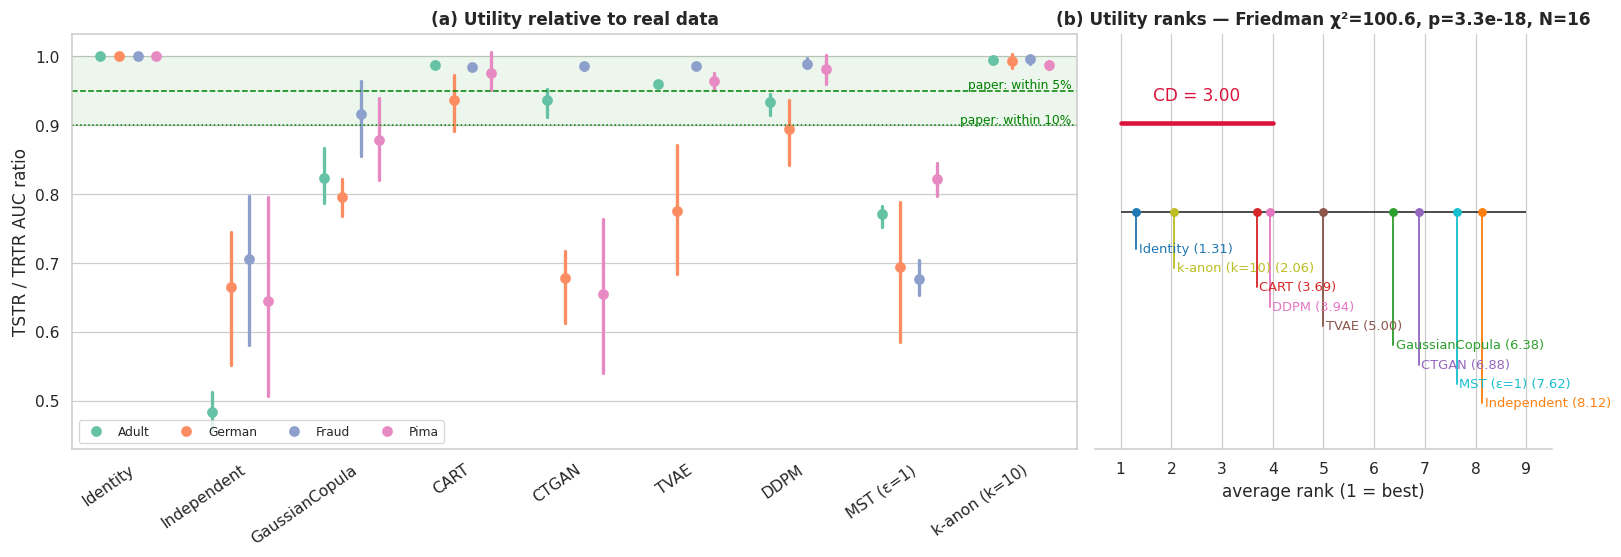

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
sns.pointplot(data=G, x="generator", y="util_ratio", hue="dataset", order=GEN_ORDER, hue_order=DS_ORDER, dodge=0.5,
              errorbar=("ci", 95), linestyles="none", markers="o", ax=ax, palette="Set2")
ax.axhspan(0.90, 1.0, color="green", alpha=0.07); ax.axhline(0.95, ls="--", c="green", lw=1); ax.axhline(0.90, ls=":", c="green", lw=1)
ax.text(8.45, 0.953, "paper: within 5%", fontsize=8, color="green", ha="right"); ax.text(8.45, 0.903, "paper: within 10%", fontsize=8, color="green", ha="right")
ax.set_ylabel("TSTR / TRTR AUC ratio"); ax.set_xlabel(""); ax.set_title("(a) Utility relative to real data"); rot(ax)
ax.legend(title="", ncol=4, loc="lower left", fontsize=8)
ranks, fst, fp, cd, nb = friedman_ranks(G, "util_ratio")
cd_plot(ranks, cd, f"(b) Utility ranks — Friedman χ²={fst:.1f}, p={fp:.1e}, N={nb}", axes[1])
plt.tight_layout(); savefig(fig, "F1_utility")

### Does the conclusion depend on the downstream model?

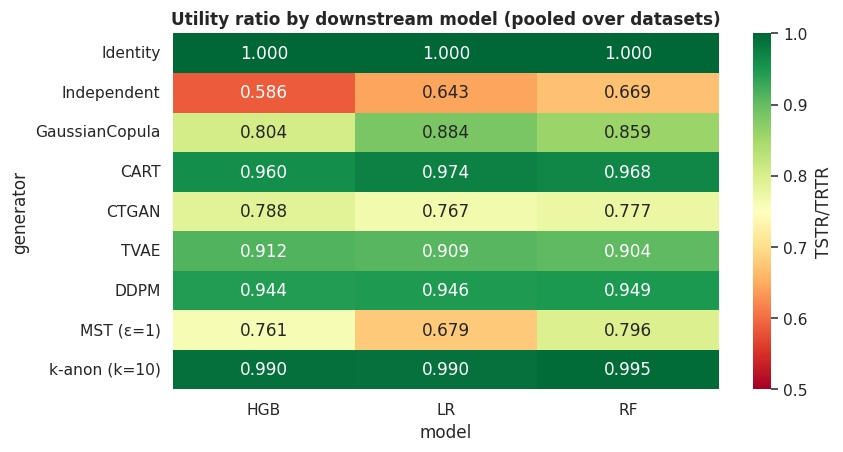

In [12]:
long = []
for m in MODELS:
    tmp = G[["dataset", "seed", "generator", f"auc_{m}"]].merge(REAL[["dataset", "seed", f"auc_{m}"]], on=["dataset", "seed"], suffixes=("", "_real"))
    tmp["ratio"] = tmp[f"auc_{m}"] / tmp[f"auc_{m}_real"]; tmp["model"] = m; long.append(tmp[["dataset", "seed", "generator", "model", "ratio"]])
long = pd.concat(long)
t3b = long.groupby(["generator", "model"]).ratio.mean().unstack().reindex(GEN_ORDER)
t3b.to_csv(f"{TAB}/T3b_utility_by_model.csv")
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(t3b, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0.5, vmax=1.0, ax=ax, cbar_kws={"label": "TSTR/TRTR"})
ax.set_title("Utility ratio by downstream model (pooled over datasets)"); savefig(fig, "F1b_utility_by_model")

## 7. Results — fidelity and diversity

dataset,Adult,German,Fraud,Pima
pair-trend score,,,,
Identity,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
Independent,0.922 ± 0.003,0.909 ± 0.004,0.864 ± 0.005,0.752 ± 0.008
GaussianCopula,0.878 ± 0.030,0.835 ± 0.023,0.620 ± 0.050,0.610 ± 0.066
CART,0.975 ± 0.005,0.926 ± 0.007,0.912 ± 0.002,0.802 ± 0.012
CTGAN,0.848 ± 0.012,0.835 ± 0.025,0.631 ± 0.047,0.601 ± 0.038
TVAE,0.826 ± 0.008,0.565 ± 0.023,0.839 ± 0.006,0.664 ± 0.019
DDPM,0.906 ± 0.035,0.489 ± 0.031,0.873 ± 0.006,0.788 ± 0.010
MST (ε=1),0.848 ± 0.015,0.740 ± 0.014,0.618 ± 0.012,0.514 ± 0.026
k-anon (k=10),0.961 ± 0.008,0.948 ± 0.004,0.946 ± 0.008,0.683 ± 0.031


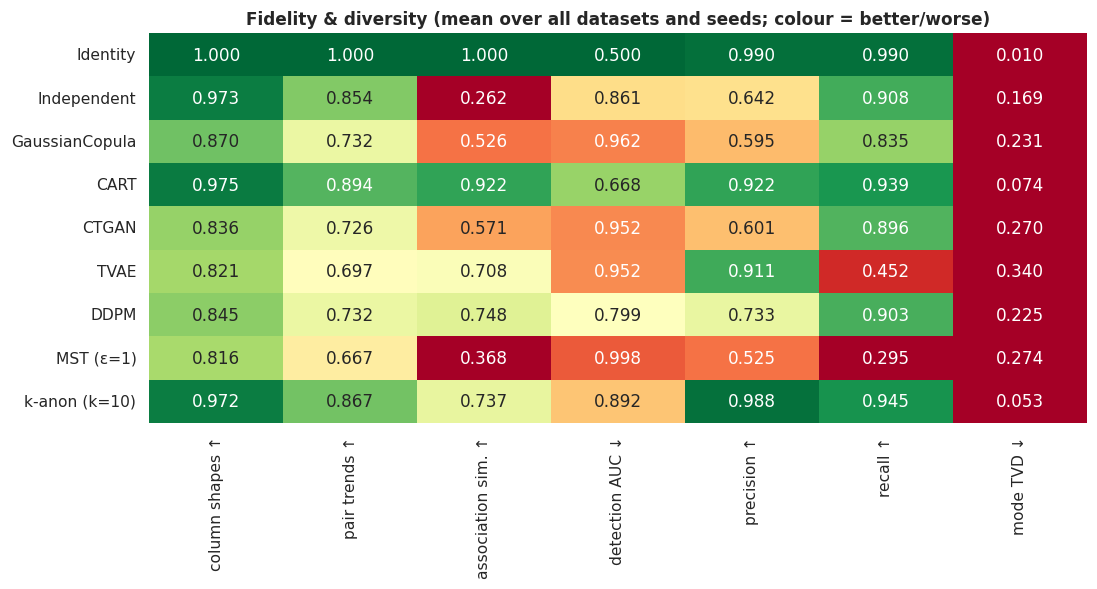

,column shapes ↑,pair trends ↑,association sim. ↑,detection AUC ↓,precision ↑,recall ↑,largest mode share,mode TVD ↓,largest mode share (real)
generator,,,,,,,,,
Identity,1.0000,1.0000,1.0000,0.4997,0.9901,0.9895,0.1178,0.0103,0.1163
Independent,0.9733,0.8539,0.2619,0.8613,0.6424,0.9076,0.1220,0.1691,0.1163
GaussianCopula,0.8704,0.7324,0.5263,0.9616,0.5949,0.8347,0.1720,0.2314,0.1163
CART,0.9746,0.8937,0.9224,0.6683,0.9217,0.9391,0.1175,0.0739,0.1163
CTGAN,0.8358,0.7261,0.5709,0.9524,0.6015,0.8957,0.1424,0.2697,0.1163
TVAE,0.8214,0.6965,0.7083,0.9518,0.9107,0.4516,0.2742,0.3396,0.1163
DDPM,0.8446,0.7325,0.7482,0.7989,0.7329,0.9026,0.2245,0.2247,0.1163
MST (ε=1),0.8160,0.6669,0.3679,0.9978,0.5255,0.2955,0.1447,0.2744,0.1163
k-anon (k=10),0.9720,0.8673,0.7367,0.8916,0.9881,0.9449,0.1216,0.0529,0.1163


In [13]:
fid_cols = {"shape": "column shapes ↑", "pair": "pair trends ↑", "assoc_sim": "association sim. ↑", "detect_auc": "detection AUC ↓",
            "precision": "precision ↑", "recall": "recall ↑", "max_mode_syn": "largest mode share", "mode_tvd": "mode TVD ↓"}
t4 = G.groupby("generator")[list(fid_cols)].mean().reindex(GEN_ORDER).rename(columns=fid_cols)
t4["largest mode share (real)"] = G.groupby("generator")["max_mode_real"].mean().reindex(GEN_ORDER).values
t4.to_csv(f"{TAB}/T4_fidelity_diversity.csv")
display(table_mean_ci(G, "pair", order=GEN_ORDER)[DS_ORDER].rename_axis("pair-trend score"))
fig, ax = plt.subplots(figsize=(11, 4.6))
show = t4.drop(columns=["largest mode share", "largest mode share (real)"]).copy()
show["detection AUC ↓"] = 1.5 - show["detection AUC ↓"]  # map 0.5→1 (good), 1.0→0.5 (bad) for the colour scale only
sns.heatmap(show, annot=t4.drop(columns=["largest mode share", "largest mode share (real)"]), fmt=".3f", cmap="RdYlGn", vmin=0.4, vmax=1, ax=ax, cbar=False)
ax.set_title("Fidelity & diversity (mean over all datasets and seeds; colour = better/worse)"); ax.set_ylabel("")
savefig(fig, "F2_fidelity_heatmap")
t4

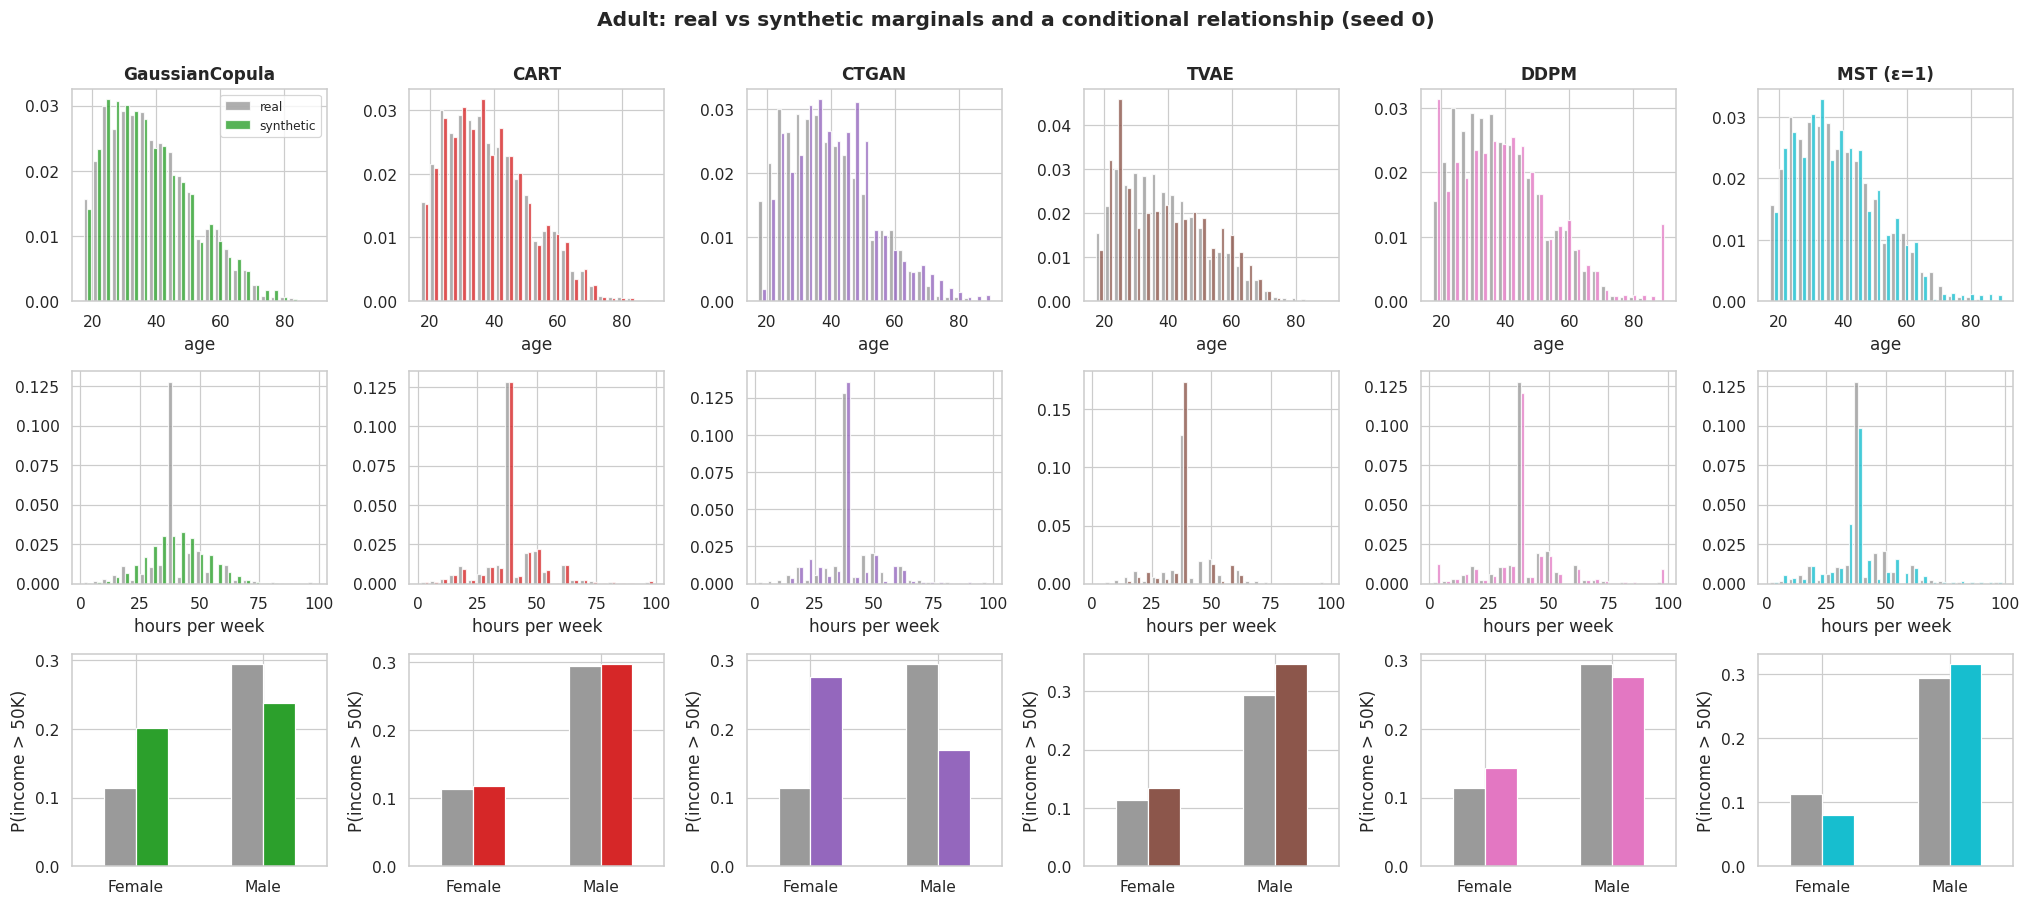

In [14]:
real_ad = make_split("adult", DATA["adult"][1]["seeds"][0])[0]
show_g = ["GaussianCopula", "CART", "CTGAN", "TVAE", "DDPM", "MST (ε=1)"]
fig, axes = plt.subplots(3, len(show_g), figsize=(3.1 * len(show_g), 8.2))
for j, g in enumerate(show_g):
    s = SAMPLES[("Adult", g)]
    axes[0, j].hist([real_ad["age"], s["age"]], bins=25, density=True, label=["real", "synthetic"], color=["#9a9a9a", PALETTE[g]], alpha=0.8)
    axes[0, j].set_title(g); axes[0, j].set_xlabel("age")
    axes[1, j].hist([real_ad["hours_per_week"], s["hours_per_week"]], bins=25, density=True, color=["#9a9a9a", PALETTE[g]], alpha=0.8); axes[1, j].set_xlabel("hours per week")
    ct = pd.DataFrame({"real": real_ad.groupby("sex")["income"].apply(lambda x: (x == ">50K").mean()),
                       "synthetic": s.groupby("sex")["income"].apply(lambda x: (x == ">50K").mean())})
    ct.plot.bar(ax=axes[2, j], color=["#9a9a9a", PALETTE[g]], legend=False, rot=0); axes[2, j].set_ylabel("P(income > 50K)"); axes[2, j].set_xlabel("")
axes[0, 0].legend(fontsize=8); plt.suptitle("Adult: real vs synthetic marginals and a conditional relationship (seed 0)", y=1.0, fontweight="bold")
plt.tight_layout(); savefig(fig, "F3_adult_marginals")

## 8. Results — privacy (claim C1: "synthetic data cannot be traced to particular individuals")

In [15]:
priv_cols = ["exact_match_syn", "exact_match_holdout_baseline", "dcr_share", "mia_auc_A1_distance", "mia_auc_A2_density_ratio",
             "mia_auc_A3_classifier_ratio", "mia_auc_max", "mia_tpr1_max", "anon_singling", "anon_link", "anon_infer"]
t5 = G.groupby("generator")[priv_cols].mean().reindex(GEN_ORDER)
t5.to_csv(f"{TAB}/T5_privacy_pooled.csv")
display(table_mean_ci(G, "mia_auc_max", order=GEN_ORDER)[DS_ORDER].rename_axis("strongest-attack MIA AUC"))
t5

dataset,Adult,German,Fraud,Pima
strongest-attack MIA AUC,,,,
Identity,0.975 ± 0.006,1.000 ± 0.000,0.998 ± 0.001,1.000 ± 0.000
Independent,0.506 ± 0.007,0.534 ± 0.008,0.513 ± 0.020,0.553 ± 0.022
GaussianCopula,0.506 ± 0.013,0.539 ± 0.009,0.509 ± 0.004,0.520 ± 0.024
CART,0.592 ± 0.006,0.621 ± 0.021,0.559 ± 0.013,0.629 ± 0.027
CTGAN,0.510 ± 0.003,0.526 ± 0.015,0.509 ± 0.009,0.512 ± 0.028
TVAE,0.515 ± 0.011,0.517 ± 0.021,0.515 ± 0.005,0.541 ± 0.021
DDPM,0.511 ± 0.017,0.548 ± 0.016,0.535 ± 0.019,0.712 ± 0.034
MST (ε=1),0.506 ± 0.008,0.523 ± 0.020,0.505 ± 0.003,0.524 ± 0.024
k-anon (k=10),0.738 ± 0.013,0.967 ± 0.005,0.908 ± 0.007,0.757 ± 0.028


,exact_match_syn,exact_match_holdout_baseline,dcr_share,mia_auc_A1_distance,mia_auc_A2_density_ratio,mia_auc_A3_classifier_ratio,mia_auc_max,mia_tpr1_max,anon_singling,anon_link,anon_infer
generator,,,,,,,,,,,
Identity,1.0000,0.0104,0.9946,0.9948,0.5602,0.6974,0.9948,0.8500,0.9936,0.9440,0.9312
Independent,0.0009,0.0104,0.5096,0.5076,0.5069,0.5302,0.5308,0.0181,0.0218,0.0113,0.0338
GaussianCopula,0.0000,0.0104,0.5205,0.5071,0.5149,0.5049,0.5214,0.0161,0.0226,0.0053,0.0277
CART,0.0310,0.0104,0.6318,0.5689,0.5506,0.6045,0.6065,0.0383,0.0876,0.1697,0.1758
CTGAN,0.0011,0.0104,0.5094,0.5022,0.5045,0.5057,0.5155,0.0156,0.0183,0.0113,0.0362
TVAE,0.0143,0.0104,0.5229,0.5111,0.5196,0.5152,0.5237,0.0177,0.0275,0.0229,0.0982
DDPM,0.0054,0.0104,0.6078,0.5813,0.5356,0.5547,0.5898,0.0651,0.0572,0.1882,0.2372
MST (ε=1),0.0000,0.0104,0.5012,0.5011,0.5072,0.5054,0.5168,0.0193,0.0249,0.0104,0.0505
k-anon (k=10),0.1046,0.0104,0.9237,0.8473,0.5607,0.5731,0.8473,0.3287,0.5225,0.4141,0.8772


### Hypothesis test for C1
For each generator and each attack: one-sided Wilcoxon signed-rank test of H₀: AUC ≤ 0.5 across all runs, Holm-corrected over all generator × attack pairs. We also count individual runs whose own Mann-Whitney test is significant (Benjamini-Hochberg within generator) and runs where Anonymeter's 95% CI lower bound is above zero.

In [16]:
tests = []
for g in GEN_ORDER:
    sub = G[G.generator == g]
    for a in ["A1_distance", "A2_density_ratio", "A3_classifier_ratio"]:
        d = sub[f"mia_auc_{a}"].values - 0.5
        p = stats.wilcoxon(d, alternative="greater").pvalue if np.any(d != 0) else 1.0
        from scipy.stats import false_discovery_control
        bh = false_discovery_control(sub[f"mia_p_{a}"].values)
        tests.append(dict(generator=g, attack=a, mean_auc=d.mean() + 0.5, runs=len(d), p_raw=p, runs_significant=int((bh < 0.05).sum()),
                          mean_tpr_at_1pct=sub[f"mia_tpr1_{a}"].mean()))
tests = pd.DataFrame(tests); tests["p_holm"] = holm(tests.p_raw); tests["significant"] = tests.p_holm < 0.05
anon_sig = G.groupby("generator").apply(lambda s: pd.Series({f"{r}: runs CI>0": int((s[f"anon_{r}_lo"] > 0).sum()) for r in ["singling", "link", "infer"]}))
tests.to_csv(f"{TAB}/T6_C1_mia_tests.csv", index=False); anon_sig.to_csv(f"{TAB}/T6b_C1_anonymeter.csv")
display(tests.pivot(index="generator", columns="attack", values="p_holm").reindex(GEN_ORDER).map(lambda p: f"{p:.2e}").rename_axis("Holm p (AUC > 0.5)"))
display(tests.pivot(index="generator", columns="attack", values="runs_significant").reindex(GEN_ORDER).rename_axis("# runs individually significant"))
anon_sig.reindex(GEN_ORDER)

attack,A1_distance,A2_density_ratio,A3_classifier_ratio
Holm p (AUC > 0.5),,,
Identity,2.08e-03,4.12e-04,4.12e-04
Independent,3.81e-02,3.33e-01,4.12e-04
GaussianCopula,1.51e-01,9.23e-03,7.45e-01
CART,4.12e-04,4.12e-04,4.12e-04
CTGAN,7.45e-01,7.45e-01,5.26e-01
TVAE,6.04e-03,6.87e-04,3.77e-03
DDPM,5.19e-04,4.12e-04,5.19e-04
MST (ε=1),7.45e-01,5.04e-01,7.45e-01
k-anon (k=10),4.12e-04,4.12e-04,4.12e-04


attack,A1_distance,A2_density_ratio,A3_classifier_ratio
# runs individually significant,,,
Identity,16,15,16
Independent,0,0,5
GaussianCopula,0,0,0
CART,16,13,16
CTGAN,0,0,0
TVAE,0,3,4
DDPM,8,11,11
MST (ε=1),0,0,0
k-anon (k=10),16,15,16


,singling: runs CI>0,link: runs CI>0,infer: runs CI>0
generator,,,
Identity,16,16,16
Independent,1,0,1
GaussianCopula,3,1,0
CART,9,14,4
CTGAN,1,0,1
TVAE,2,1,1
DDPM,6,7,7
MST (ε=1),2,0,1
k-anon (k=10),16,16,16


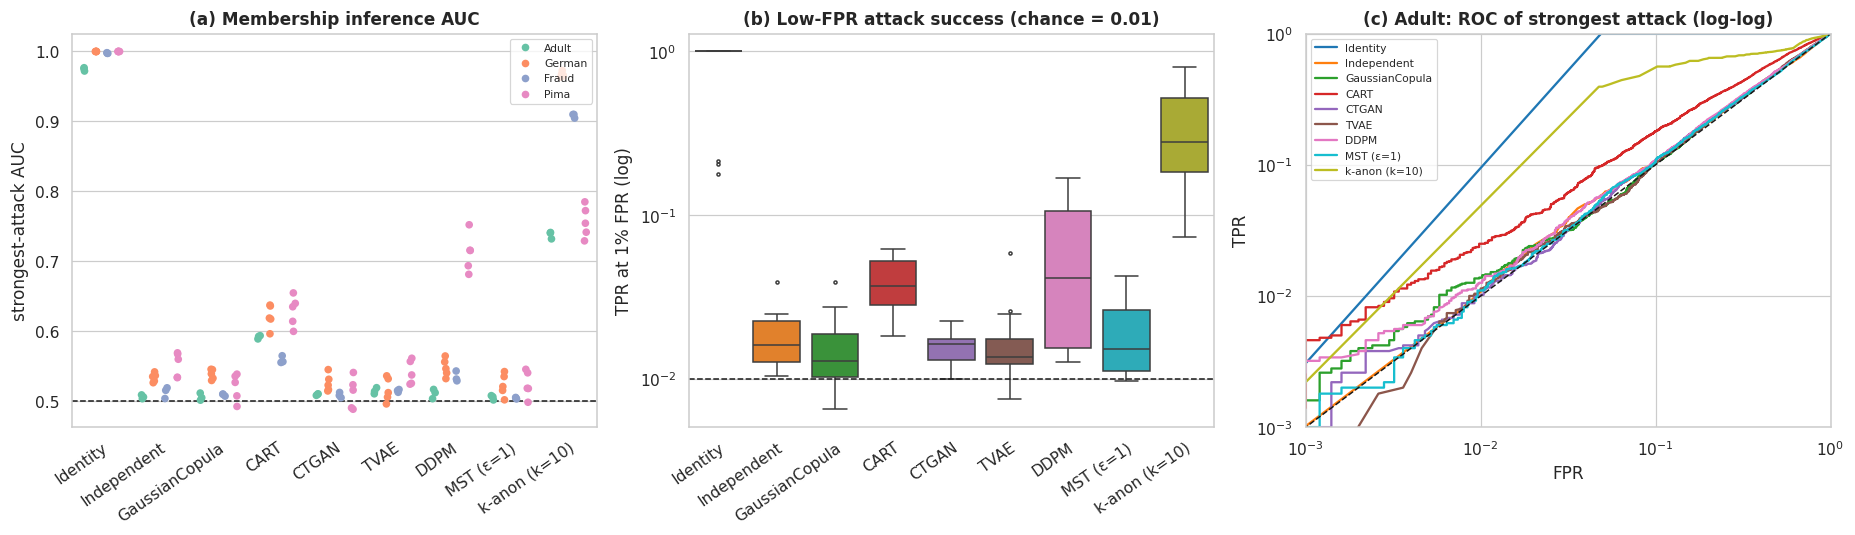

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.stripplot(data=G, x="generator", y="mia_auc_max", hue="dataset", order=GEN_ORDER, hue_order=DS_ORDER, dodge=True, ax=axes[0], palette="Set2", size=5)
axes[0].axhline(0.5, c="k", ls="--", lw=1); axes[0].set_ylabel("strongest-attack AUC"); axes[0].set_title("(a) Membership inference AUC"); rot(axes[0]); axes[0].set_xlabel("")
axes[0].legend(fontsize=7, loc="upper right")
sns.boxplot(data=G, x="generator", y="mia_tpr1_max", order=GEN_ORDER, ax=axes[1], palette=PALETTE, fliersize=2)
axes[1].axhline(0.01, c="k", ls="--", lw=1); axes[1].set_yscale("log"); axes[1].set_ylabel("TPR at 1% FPR (log)"); axes[1].set_title("(b) Low-FPR attack success (chance = 0.01)")
rot(axes[1]); axes[1].set_xlabel("")
key = ("Adult", None, DATA["adult"][1]["seeds"][0])
for g in GEN_ORDER:
    yT, sc = SCORES[("Adult", g, key[2])]
    a = max(sc, key=lambda k: roc_auc_score(yT, sc[k])); fpr, tpr, _ = roc_curve(yT, sc[a])
    axes[2].plot(np.maximum(fpr, 1e-4), np.maximum(tpr, 1e-4), color=PALETTE[g], label=f"{g}", lw=1.5)
axes[2].plot([1e-4, 1], [1e-4, 1], "k--", lw=1); axes[2].set_xscale("log"); axes[2].set_yscale("log"); axes[2].set_xlim(1e-3, 1); axes[2].set_ylim(1e-3, 1)
axes[2].set_xlabel("FPR"); axes[2].set_ylabel("TPR"); axes[2].set_title("(c) Adult: ROC of strongest attack (log-log)"); axes[2].legend(fontsize=7)
plt.tight_layout(); savefig(fig, "F4_membership_inference")

### Who is at risk? Outliers vs typical records
Stadler et al. (2022) argued that synthetic data protects average records but not outliers. Outlierness is measured against the attacker's reference sample only (blind to membership); the top 10% most isolated targets are "outliers".

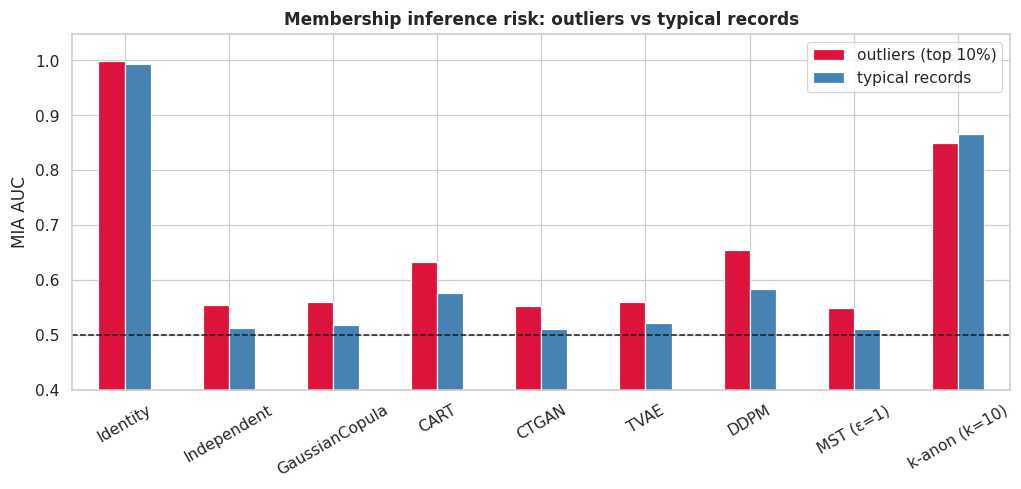

,mia_auc_outlier,mia_auc_inlier,"p (outlier > inlier, Wilcoxon)"
generator,,,
Identity,0.9985,0.9944,1.7272e-01
Independent,0.5552,0.5131,1.0696e-02
GaussianCopula,0.5592,0.5181,2.2156e-02
CART,0.6322,0.5755,1.0681e-03
CTGAN,0.5533,0.5112,1.9318e-02
TVAE,0.5595,0.5218,3.2700e-02
DDPM,0.6541,0.5838,7.6294e-05
MST (ε=1),0.5496,0.5101,9.1248e-03
k-anon (k=10),0.8499,0.8652,8.3875e-01


In [18]:
ov = G[["generator", "dataset", "mia_auc_outlier", "mia_auc_inlier"]].dropna()
t7 = ov.groupby("generator")[["mia_auc_outlier", "mia_auc_inlier"]].mean().reindex(GEN_ORDER)
t7["p (outlier > inlier, Wilcoxon)"] = [stats.wilcoxon(ov[ov.generator == g].mia_auc_outlier, ov[ov.generator == g].mia_auc_inlier, alternative="greater").pvalue
                                        if g in ov.generator.values else np.nan for g in t7.index]
t7.to_csv(f"{TAB}/T7_outlier_vulnerability.csv")
fig, ax = plt.subplots(figsize=(11, 4.2))
t7[["mia_auc_outlier", "mia_auc_inlier"]].rename(columns={"mia_auc_outlier": "outliers (top 10%)", "mia_auc_inlier": "typical records"}).plot.bar(ax=ax, color=["crimson", "steelblue"], rot=30)
ax.axhline(0.5, c="k", ls="--", lw=1); ax.set_ylim(0.4, None); ax.set_ylabel("MIA AUC"); ax.set_title("Membership inference risk: outliers vs typical records"); ax.set_xlabel("")
savefig(fig, "F5_outlier_risk"); t7

### Does the vendor-style DCR check catch leakage? (claim C11, part 1)
Commercial synthetic-data tools usually certify privacy with a *distance-to-closest-record* test. Here we plot, for every run, the DCR share against the success of the strongest membership attack.

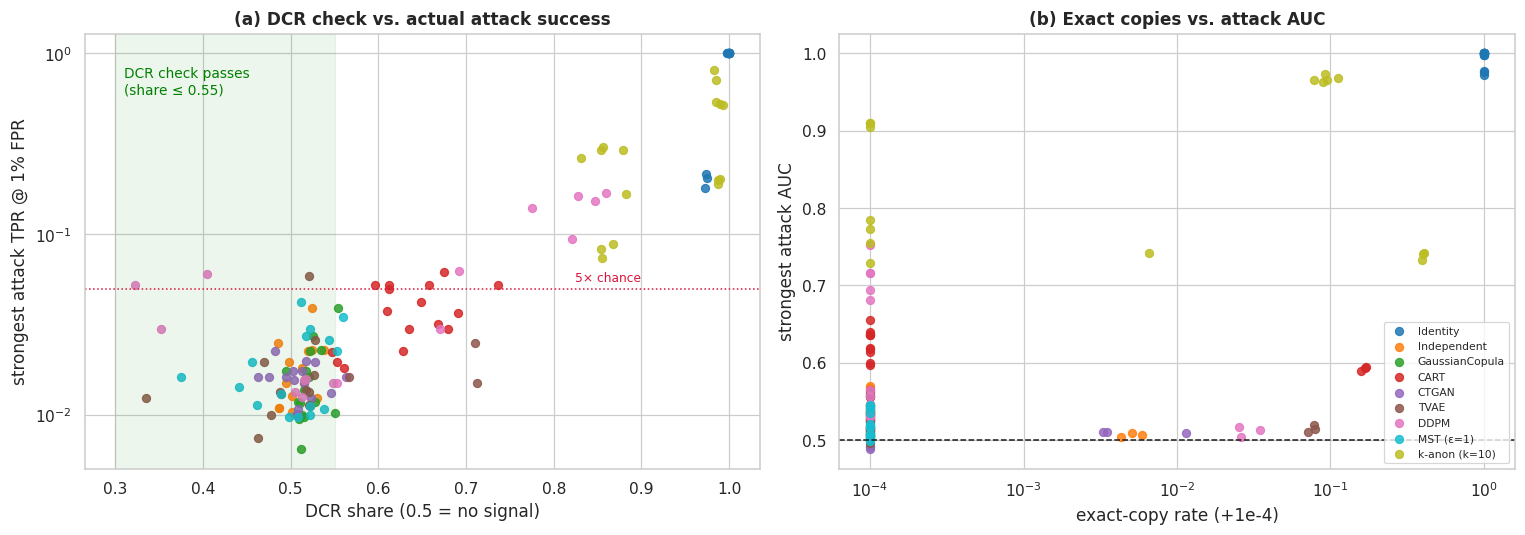

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for g in GEN_ORDER:
    s = G[G.generator == g]
    axes[0].scatter(s.dcr_share, s.mia_tpr1_max, label=g, color=PALETTE[g], s=28, alpha=0.85)
    axes[1].scatter(s.exact_match_syn + 1e-4, s.mia_auc_max, label=g, color=PALETTE[g], s=28, alpha=0.85)
axes[0].axvspan(0.3, 0.55, color="green", alpha=0.07); axes[0].text(0.31, 0.6, "DCR check passes\n(share ≤ 0.55)", color="green", fontsize=9)
axes[0].axhline(0.05, c="crimson", ls=":", lw=1); axes[0].text(0.9, 0.055, "5× chance", color="crimson", fontsize=8, ha="right")
axes[0].set_yscale("log"); axes[0].set_xlabel("DCR share (0.5 = no signal)"); axes[0].set_ylabel("strongest attack TPR @ 1% FPR"); axes[0].set_title("(a) DCR check vs. actual attack success")
axes[1].set_xscale("log"); axes[1].set_xlabel("exact-copy rate (+1e-4)"); axes[1].set_ylabel("strongest attack AUC"); axes[1].axhline(0.5, c="k", ls="--", lw=1)
axes[1].set_title("(b) Exact copies vs. attack AUC"); axes[1].legend(fontsize=7, loc="lower right")
plt.tight_layout(); savefig(fig, "F6_dcr_vs_mia")

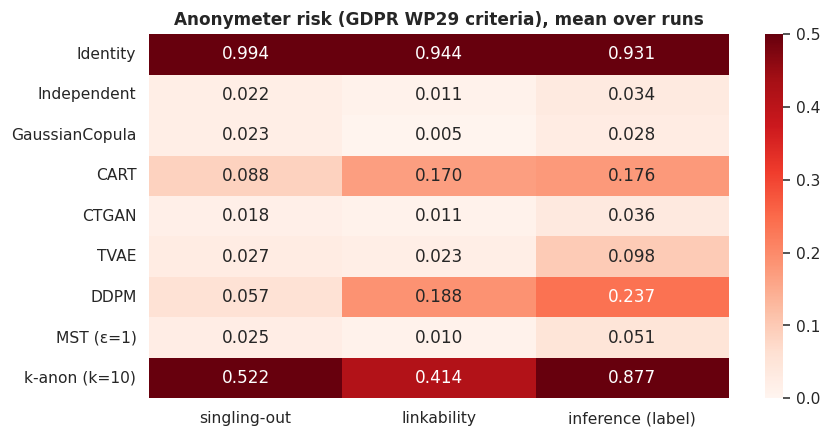

In [20]:
fig, ax = plt.subplots(figsize=(8.5, 4.3))
an = G.groupby("generator")[["anon_singling", "anon_link", "anon_infer"]].mean().reindex(GEN_ORDER)
sns.heatmap(an.rename(columns={"anon_singling": "singling-out", "anon_link": "linkability", "anon_infer": "inference (label)"}), annot=True, fmt=".3f", cmap="Reds", vmin=0, vmax=0.5, ax=ax)
ax.set_title("Anonymeter risk (GDPR WP29 criteria), mean over runs"); ax.set_ylabel(""); savefig(fig, "F7_anonymeter")

## 9. Results — fairness (claim C4: synthetic data amplifies bias)
For each protected attribute we compare, synthetic vs. the real training data it was fitted on:
* **base-rate gap**: P(positive | reference group) − P(positive | protected group) in the released data;
* **representation**: share of the protected group;
* **downstream**: equalized-odds difference and protected-group AUC of a gradient-boosting model trained on the data and tested on real data.

In [21]:
fair_rows = []
for _, r in G.iterrows():
    meta = [m for _, m in DATA.values() if m["name"] == r.dataset][0]
    for a in meta["sensitive"]:
        fair_rows.append(dict(dataset=r.dataset, seed=r.seed, generator=r.generator, attr=f"{r.dataset}:{a}",
            gap_real=r[f"{a}|base_gap_real"], gap_syn=r[f"{a}|base_gap"], share_real=r[f"{a}|share_unpriv_real"], share_syn=r[f"{a}|share_unpriv"],
            eo_real=r[f"{a}|eo_diff_real"], eo_syn=r[f"{a}|eo_diff"], auc_unpriv_real=r[f"{a}|auc_unpriv_real"], auc_unpriv_syn=r[f"{a}|auc_unpriv"],
            auc_priv_real=r[f"{a}|auc_priv_real"], auc_priv_syn=r[f"{a}|auc_priv"]))
FR = pd.DataFrame(fair_rows)
FR["gap_amplified"] = FR.gap_syn.abs() > FR.gap_real.abs()
FR["gap_change"] = FR.gap_syn.abs() - FR.gap_real.abs()
FR["repr_ratio"] = FR.share_syn / FR.share_real
FR["drop_unpriv"] = FR.auc_unpriv_real - FR.auc_unpriv_syn; FR["drop_priv"] = FR.auc_priv_real - FR.auc_priv_syn
FR["extra_drop_protected"] = FR.drop_unpriv - FR.drop_priv
FR.to_csv(f"{TAB}/fairness_long.csv", index=False)

def sign_p(x):  # two-sided sign test on the direction of change
    x = x[x != 0]; return stats.binomtest(int((x > 0).sum()), len(x), 0.5).pvalue if len(x) else np.nan
t8 = FR.groupby("generator").apply(lambda s: pd.Series({
    "runs": len(s), "share of runs gap amplified": s.gap_amplified.mean(), "mean |gap| change": s.gap_change.mean(),
    "sign-test p (gap)": sign_p(s.gap_change.values), "representation ratio": s.repr_ratio.mean(),
    "EO diff real": s.eo_real.mean(), "EO diff synthetic": s.eo_syn.mean(),
    "Wilcoxon p (EO syn>real)": stats.wilcoxon(s.eo_syn, s.eo_real, alternative="greater").pvalue if (s.eo_syn != s.eo_real).any() else np.nan,
    "extra AUC drop for protected group": s.extra_drop_protected.mean(),
    "Wilcoxon p (extra drop>0)": stats.wilcoxon(s.extra_drop_protected.dropna(), alternative="greater").pvalue if s.extra_drop_protected.abs().sum() > 0 else np.nan})).reindex(GEN_ORDER)
t8.to_csv(f"{TAB}/T8_fairness.csv"); t8

,runs,share of runs gap amplified,mean |gap| change,sign-test p (gap),representation ratio,EO diff real,EO diff synthetic,Wilcoxon p (EO syn>real),extra AUC drop for protected group,Wilcoxon p (extra drop>0)
generator,,,,,,,,,,
Identity,21.0,0.0000,0.0000,NaN,1.0000,0.18,0.1800,NaN,0.0000,NaN
Independent,21.0,0.0476,-0.1350,2.0981e-05,0.9979,0.18,0.1231,0.9727,0.0016,0.5271
GaussianCopula,21.0,0.0000,-0.1242,9.5367e-07,1.0319,0.18,0.1499,0.8312,0.0066,0.5136
CART,21.0,0.1429,-0.0292,1.4896e-03,0.9853,0.18,0.1894,0.2262,-0.0029,0.5809
CTGAN,21.0,0.0952,-0.1137,2.2125e-04,1.1192,0.18,0.1656,0.6073,-0.0426,0.9105
TVAE,21.0,0.4762,-0.0395,1.0000e+00,0.8029,0.18,0.1431,0.6834,-0.0081,0.7738
DDPM,21.0,0.4286,0.0943,6.6362e-01,1.5483,0.18,0.2295,0.0686,0.0163,0.0953
MST (ε=1),21.0,0.5238,0.0333,1.0000e+00,0.9484,0.18,0.2137,0.2474,-0.0200,0.7416
k-anon (k=10),21.0,0.2381,-0.0059,1.0000e+00,0.9478,0.18,0.1777,0.6316,-0.0018,0.6954


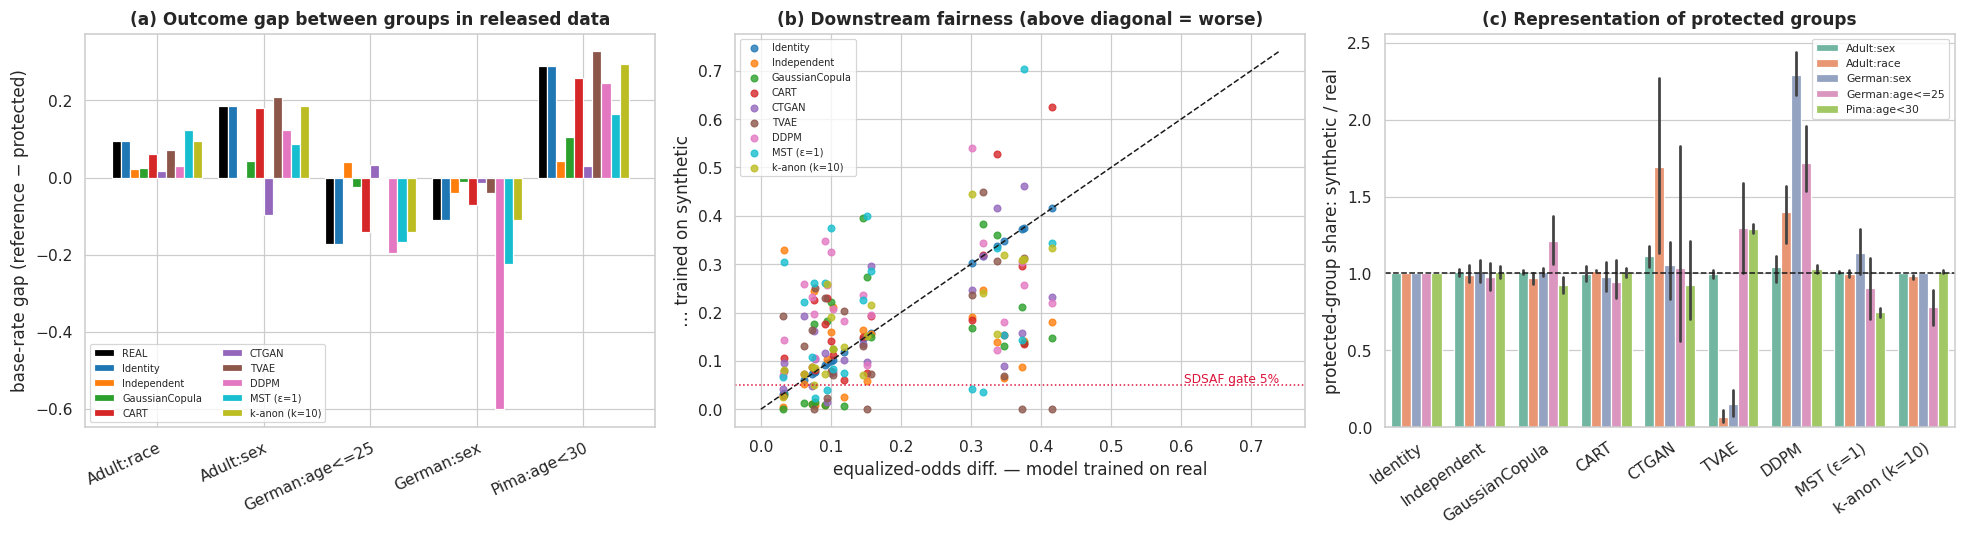

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
agg = FR.groupby(["attr", "generator"]).agg(gap_real=("gap_real", "mean"), gap_syn=("gap_syn", "mean")).reset_index()
piv = agg.pivot(index="attr", columns="generator", values="gap_syn")[GEN_ORDER]
piv.insert(0, "REAL", agg.groupby("attr").gap_real.first())
piv.plot.bar(ax=axes[0], color=["black"] + [PALETTE[g] for g in GEN_ORDER], width=0.85, rot=0)
axes[0].set_ylabel("base-rate gap (reference − protected)"); axes[0].set_title("(a) Outcome gap between groups in released data"); axes[0].legend(fontsize=6.5, ncol=2); axes[0].set_xlabel(""); rot(axes[0], 25)
for g in GEN_ORDER:
    s = FR[FR.generator == g]; axes[1].scatter(s.eo_real, s.eo_syn, color=PALETTE[g], s=20, alpha=0.8, label=g)
lim = [0, max(FR.eo_real.max(), FR.eo_syn.max()) * 1.05]; axes[1].plot(lim, lim, "k--", lw=1); axes[1].axhline(0.05, c="crimson", ls=":", lw=1)
axes[1].text(lim[1], 0.055, "SDSAF gate 5%", color="crimson", fontsize=8, ha="right")
axes[1].set_xlabel("equalized-odds diff. — model trained on real"); axes[1].set_ylabel("… trained on synthetic"); axes[1].set_title("(b) Downstream fairness (above diagonal = worse)")
axes[1].legend(fontsize=6.5)
sns.barplot(data=FR, x="generator", y="repr_ratio", order=GEN_ORDER, hue="attr", ax=axes[2], errorbar=("ci", 95), palette="Set2")
axes[2].axhline(1, c="k", ls="--", lw=1); axes[2].set_ylabel("protected-group share: synthetic / real"); rot(axes[2]); axes[2].set_xlabel("")
axes[2].set_title("(c) Representation of protected groups"); axes[2].legend(fontsize=7)
plt.tight_layout(); savefig(fig, "F8_fairness")

## 10. Results — energy and storage (claims C7, C8)
The paper states that synthetic data pipelines cut energy use by 30–60% and storage by 40–60%. Here both pipelines are measured on the same machine:
* **real pipeline** = train the three downstream models on real data;
* **synthetic pipeline** = fit the generator + sample + train the same three models on synthetic data.

The costs of collecting real data (surveys, sensors, consent management) are outside what a computer can measure; the paper's claim concerns compute and storage, which is what is measured here.

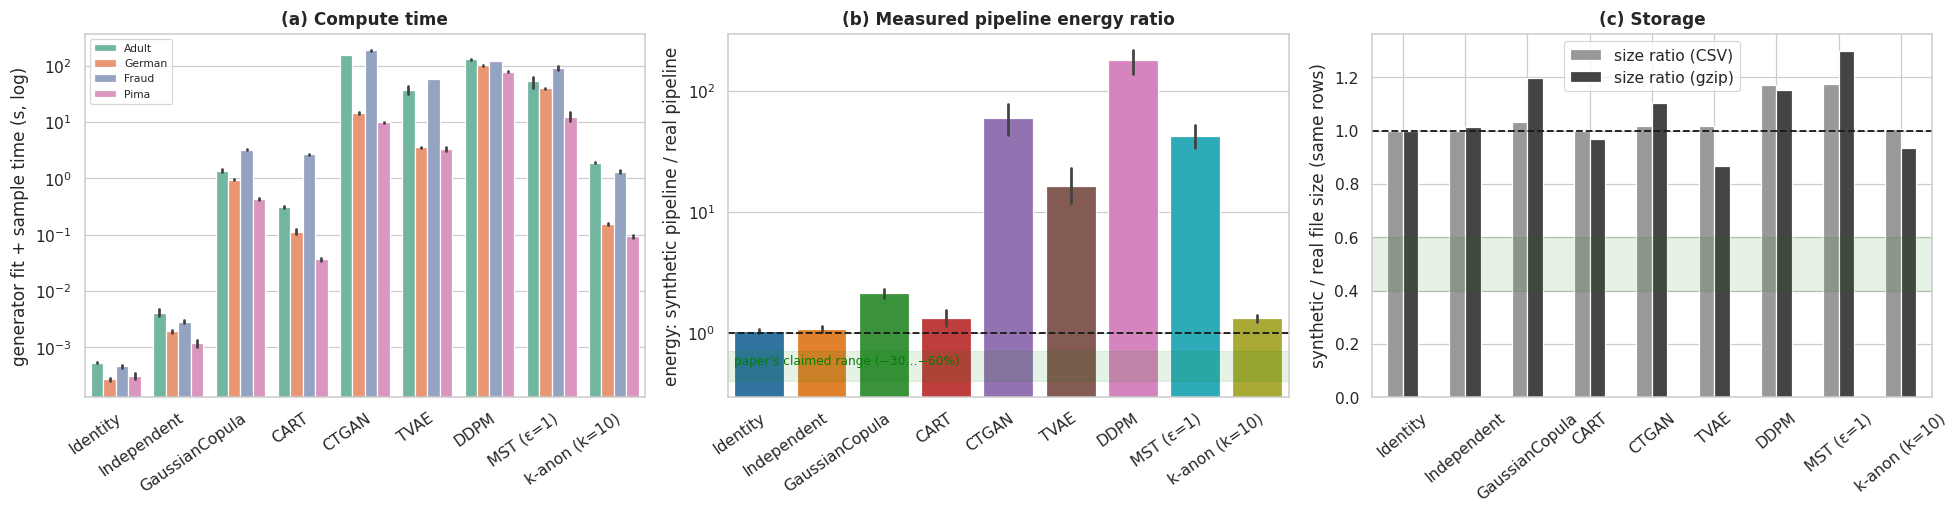

,gen_seconds,gen_Wh,gen_gCO2,real_pipeline_Wh,synthetic_pipeline_Wh,energy_ratio_syn_over_real
generator,,,,,,
Identity,0.0004,1.1801e-06,5.1996e-07,0.0042,0.0043,1.0238
Independent,0.0022,1.3252e-06,5.8390e-07,0.0042,0.0046,1.0572
GaussianCopula,1.2952,4.5489e-03,2.0043e-03,0.0042,0.0086,2.1384
CART,0.6026,2.1474e-03,9.4618e-04,0.0042,0.0064,1.1350
CTGAN,72.1482,3.5493e-01,1.5639e-01,0.0042,0.3594,35.7846
TVAE,20.0041,9.4745e-02,4.1745e-02,0.0042,0.0978,9.5862
DDPM,103.5153,5.1468e-01,2.2677e-01,0.0042,0.5190,227.1314
MST (ε=1),43.0503,1.5070e-01,6.6400e-02,0.0042,0.1542,37.7639
k-anon (k=10),0.6800,2.3540e-03,1.0372e-03,0.0042,0.0059,1.2479


,size ratio (CSV),size ratio (gzip)
generator,,
Identity,1.0000,1.0000
Independent,0.9998,1.0121
GaussianCopula,1.0306,1.1955
CART,0.9998,0.9672
CTGAN,1.0186,1.1025
TVAE,1.0156,0.8677
DDPM,1.1712,1.1522
MST (ε=1),1.1746,1.2986
k-anon (k=10),1.0057,0.9342


In [23]:
E = G.merge(REAL[["dataset", "seed", "down_kwh", "down_seconds"]].rename(columns={"down_kwh": "real_kwh", "down_seconds": "real_seconds"}), on=["dataset", "seed"])
E["syn_pipeline_kwh"] = E.gen_kwh + E.down_kwh; E["pipeline_ratio"] = E.syn_pipeline_kwh / E.real_kwh
t9 = E.groupby("generator").agg(gen_seconds=("gen_seconds", "mean"), gen_Wh=("gen_kwh", lambda x: 1000 * x.mean()), gen_gCO2=("gen_co2_kg", lambda x: 1000 * x.mean()),
                                  real_pipeline_Wh=("real_kwh", lambda x: 1000 * x.mean()), synthetic_pipeline_Wh=("syn_pipeline_kwh", lambda x: 1000 * x.mean()),
                                  energy_ratio_syn_over_real=("pipeline_ratio", "median")).reindex(GEN_ORDER)
t9.to_csv(f"{TAB}/T9_energy.csv")

def csv_bytes(df, gz=False):
    b = df.to_csv(index=False).encode()
    if gz:
        import gzip; b = gzip.compress(b)
    return len(b)
st = []
for (dname, g), s in SAMPLES.items():
    key = [k for k, (_, m) in DATA.items() if m["name"] == dname][0]
    real_tr = make_split(key, DATA[key][1]["seeds"][0])[0]
    st.append(dict(dataset=dname, generator=g, raw_ratio=csv_bytes(s) / csv_bytes(real_tr), gzip_ratio=csv_bytes(s, True) / csv_bytes(real_tr, True)))
ST = pd.DataFrame(st); t9b = ST.groupby("generator")[["raw_ratio", "gzip_ratio"]].mean().reindex(GEN_ORDER)
t9b.columns = ["size ratio (CSV)", "size ratio (gzip)"]; t9b.to_csv(f"{TAB}/T9b_storage.csv")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.barplot(data=E, x="generator", y="gen_seconds", order=GEN_ORDER, hue="dataset", hue_order=DS_ORDER, ax=axes[0], palette="Set2")
axes[0].set_yscale("log"); axes[0].set_ylabel("generator fit + sample time (s, log)"); rot(axes[0]); axes[0].set_xlabel(""); axes[0].set_title("(a) Compute time"); axes[0].legend(fontsize=7)
sns.barplot(data=E, x="generator", y="pipeline_ratio", order=GEN_ORDER, ax=axes[1], palette=PALETTE, errorbar=("ci", 95))
axes[1].axhline(1, c="k", ls="--"); axes[1].axhspan(0.4, 0.7, color="green", alpha=0.1); axes[1].text(-0.4, 0.55, "paper's claimed range (−30…−60%)", color="green", fontsize=8)
axes[1].set_yscale("log"); axes[1].set_ylabel("energy: synthetic pipeline / real pipeline"); rot(axes[1]); axes[1].set_xlabel(""); axes[1].set_title("(b) Measured pipeline energy ratio")
t9b.plot.bar(ax=axes[2], rot=40, color=["#999", "#444"]); axes[2].axhline(1, c="k", ls="--"); axes[2].axhspan(0.4, 0.6, color="green", alpha=0.1)
axes[2].set_ylabel("synthetic / real file size (same rows)"); axes[2].set_title("(c) Storage"); axes[2].set_xlabel("")
plt.tight_layout(); savefig(fig, "F9_energy_storage")
display(t9); t9b

## 11. Experiment E3 — the privacy–utility–fairness frontier under differential privacy (claim C6)
MST is run at ε ∈ {0.1, 0.3, 1, 3, 10, 100} on Adult (3 seeds) and German (5 seeds). Smaller ε = stronger formal privacy. For each run we record utility, fidelity, membership-inference success and **per-group** utility, to test whether privacy costs are paid disproportionately by protected groups.

Adult  s0 ε=0.1   util=0.666 MIA=0.510 TPR@1%=0.013


Adult  s0 ε=0.3   util=0.778 MIA=0.507 TPR@1%=0.012


Adult  s0 ε=1.0   util=0.842 MIA=0.507 TPR@1%=0.011


Adult  s0 ε=3.0   util=0.846 MIA=0.508 TPR@1%=0.012


Adult  s0 ε=10.0  util=0.846 MIA=0.511 TPR@1%=0.014


Adult  s0 ε=100.0 util=0.844 MIA=0.511 TPR@1%=0.014


... (38 outputs left out)

German s4 ε=1.0   util=0.615 MIA=0.532 TPR@1%=0.025


German s4 ε=3.0   util=0.779 MIA=0.512 TPR@1%=0.022


German s4 ε=10.0  util=0.840 MIA=0.525 TPR@1%=0.010


German s4 ε=100.0 util=0.934 MIA=0.516 TPR@1%=0.022


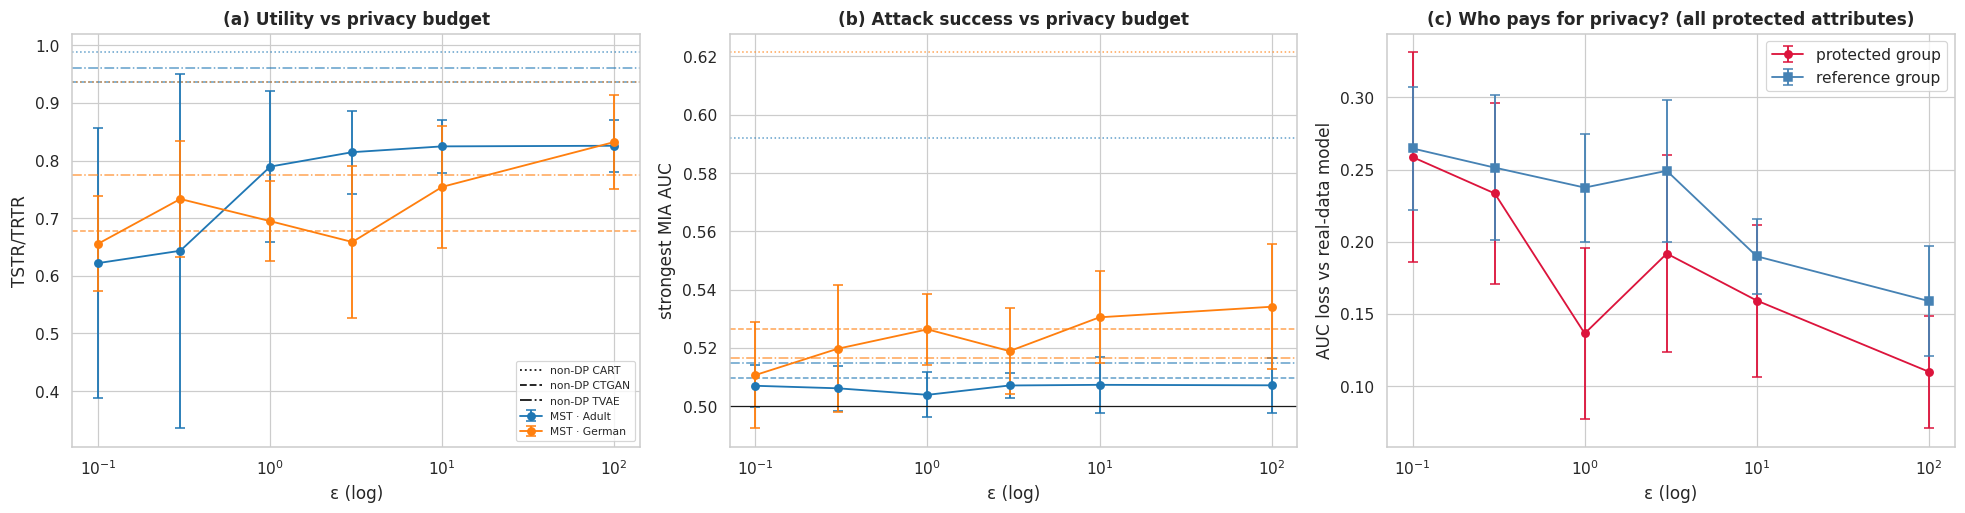

,n,"AUC drop, protected","AUC drop, reference",extra drop (protected − reference),Wilcoxon p (extra > 0),Holm p
eps,,,,,,
0.1,16.0,0.2586,0.2646,-0.0060,0.6657,1.0
0.3,16.0,0.2335,0.2513,-0.0179,0.7359,1.0
1.0,16.0,0.1364,0.2375,-0.1011,0.9974,1.0
3.0,16.0,0.1918,0.2491,-0.0574,0.9036,1.0
10.0,16.0,0.1592,0.1899,-0.0307,0.8943,1.0
100.0,16.0,0.1099,0.1589,-0.0490,0.9477,1.0


In [24]:
dp_rows = []
for key in ["adult", "german"]:
    df, meta = DATA[key]
    for seed in meta["seeds"]:
        tr, ho, te = make_split(key, seed); enc = Encoder(tr, meta)
        u_real, p_real = utility(tr, te, meta, seed); f_real = fairness(tr, te, p_real, meta)
        for eps in CFG["dp_eps_grid"]:
            syn = _postprocess(gen_mst(tr, meta, seed, eps=eps), tr, meta)
            u, p = utility(syn, te, meta, seed); f = fairness(syn, te, p, meta)
            pv = privacy(tr, ho, te, syn, meta, enc, seed, anonymeter_on=False); pv.pop("_scores")
            fid = fidelity(tr, syn, meta, seed, holdout=ho)
            r = dict(dataset=meta["name"], seed=seed, eps=eps, util_ratio=u["auc_mean"] / u_real["auc_mean"], auc_HGB=u["auc_HGB"],
                     pair=fid["pair"], mia_auc_max=pv["mia_auc_max"], mia_tpr1_max=pv["mia_tpr1_max"], dcr_share=pv["dcr_share"])
            for a in meta["sensitive"]:
                r[f"{a}|drop_unpriv"] = f_real[f"{a}|auc_unpriv"] - f[f"{a}|auc_unpriv"]
                r[f"{a}|drop_priv"] = f_real[f"{a}|auc_priv"] - f[f"{a}|auc_priv"]
                r[f"{a}|eo_syn"] = f[f"{a}|eo_diff"]; r[f"{a}|eo_real"] = f_real[f"{a}|eo_diff"]
            dp_rows.append(r)
            print(f"{meta['name']:<6} s{seed} ε={eps:<5} util={r['util_ratio']:.3f} MIA={r['mia_auc_max']:.3f} TPR@1%={r['mia_tpr1_max']:.3f}", flush=True)
DP = pd.DataFrame(dp_rows); DP.to_csv(f"{TAB}/E3_dp_sweep.csv", index=False)

DPL = []
for _, r in DP.iterrows():
    for c in [c for c in DP.columns if c.endswith("|drop_unpriv")]:
        a = c.split("|")[0]
        if pd.notna(r[c]): DPL.append(dict(dataset=r.dataset, seed=r.seed, eps=r.eps, attr=f"{r.dataset}:{a}", drop_protected=r[c], drop_reference=r[f"{a}|drop_priv"]))
DPL = pd.DataFrame(DPL); DPL["extra_drop"] = DPL.drop_protected - DPL.drop_reference
t10 = DPL.groupby("eps").apply(lambda s: pd.Series({"n": len(s), "AUC drop, protected": s.drop_protected.mean(), "AUC drop, reference": s.drop_reference.mean(),
        "extra drop (protected − reference)": s.extra_drop.mean(), "Wilcoxon p (extra > 0)": stats.wilcoxon(s.extra_drop, alternative="greater").pvalue}))
t10["Holm p"] = holm(t10["Wilcoxon p (extra > 0)"]); t10.to_csv(f"{TAB}/T10_dp_fairness.csv")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for dname, c in zip(["Adult", "German"], ["tab:blue", "tab:orange"]):
    s = DP[DP.dataset == dname].groupby("eps")
    for ax, col in zip(axes[:2], ["util_ratio", "mia_auc_max"]):
        m, h = s[col].mean(), s[col].agg(ci_t); ax.errorbar(m.index, m, yerr=h, marker="o", capsize=3, label=f"MST · {dname}", color=c)
    for g, ls in [("CART", ":"), ("CTGAN", "--"), ("TVAE", "-.")]:
        axes[0].axhline(G[(G.dataset == dname) & (G.generator == g)].util_ratio.mean(), color=c, ls=ls, lw=1, alpha=0.7)
        axes[1].axhline(G[(G.dataset == dname) & (G.generator == g)].mia_auc_max.mean(), color=c, ls=ls, lw=1, alpha=0.7)
for ax, t, yl in [(axes[0], "(a) Utility vs privacy budget", "TSTR/TRTR"), (axes[1], "(b) Attack success vs privacy budget", "strongest MIA AUC")]:
    ax.set_xscale("log"); ax.set_xlabel("ε (log)"); ax.set_title(t); ax.set_ylabel(yl)
axes[0].plot([], [], "k:", label="non-DP CART"); axes[0].plot([], [], "k--", label="non-DP CTGAN"); axes[0].plot([], [], "k-.", label="non-DP TVAE"); axes[0].legend(fontsize=7)
axes[1].axhline(0.5, c="k", lw=0.8)
m = DPL.groupby(["eps"])[["drop_protected", "drop_reference"]].mean(); h = DPL.groupby(["eps"])[["drop_protected", "drop_reference"]].agg(ci_t)
axes[2].errorbar(m.index, m.drop_protected, yerr=h.drop_protected, marker="o", capsize=3, color="crimson", label="protected group")
axes[2].errorbar(m.index, m.drop_reference, yerr=h.drop_reference, marker="s", capsize=3, color="steelblue", label="reference group")
axes[2].set_xscale("log"); axes[2].set_xlabel("ε (log)"); axes[2].set_ylabel("AUC loss vs real-data model"); axes[2].set_title("(c) Who pays for privacy? (all protected attributes)"); axes[2].legend()
plt.tight_layout(); savefig(fig, "F10_dp_frontier"); t10

## 12. Experiment E5 — synthetic data under data scarcity (proposition P2 / claim C9)
Adult, real training size n ∈ {50, 100, 250, 500, 1,000, 2,500}, 3 seeds, fixed 5,000-row real test set. For each n we compare **real only**, **synthetic only** (5,000 rows from a generator fitted on the n real rows) and **real + synthetic** (augmentation).

In [25]:
SC_N = [50, 100, 250, 500, 1000, 2500] if not QUICK else [100, 500]
SC_GENS = {"GaussianCopula": gen_gc, "CART": gen_cart, "CTGAN": gen_ctgan, "TVAE": gen_tvae}
df_ad, meta_ad = DATA["adult"]; sc_rows = []
for seed in DATA["adult"][1]["seeds"]:
    tr_full, _, te = make_split("adult", seed)
    for n in SC_N:
        tr = tr_full.sample(n, random_state=seed).reset_index(drop=True)
        if tr[meta_ad["target"]].nunique() < 2: continue
        u, _ = utility(tr, te, meta_ad, seed); sc_rows.append(dict(seed=seed, n=n, generator="—", condition="real only", auc=u["auc_mean"], auc_LR=u["auc_LR"], auc_HGB=u["auc_HGB"]))
        for g, fn in SC_GENS.items():
            syn = _postprocess(fn(tr, meta_ad, seed, n=5000), tr, meta_ad)
            for cond, data in [("synthetic only", syn), ("real + synthetic", pd.concat([tr, syn], ignore_index=True))]:
                u, _ = utility(data, te, meta_ad, seed); sc_rows.append(dict(seed=seed, n=n, generator=g, condition=cond, auc=u["auc_mean"], auc_LR=u["auc_LR"], auc_HGB=u["auc_HGB"]))
        print(f"seed {seed} n={n} done", flush=True)
SC = pd.DataFrame(sc_rows); SC.to_csv(f"{TAB}/E5_scarcity.csv", index=False)

seed 0 n=50 done


seed 0 n=100 done


seed 0 n=250 done


seed 0 n=500 done


seed 0 n=1000 done


seed 0 n=2500 done


... (8 outputs left out)

seed 2 n=250 done


seed 2 n=500 done


seed 2 n=1000 done


seed 2 n=2500 done


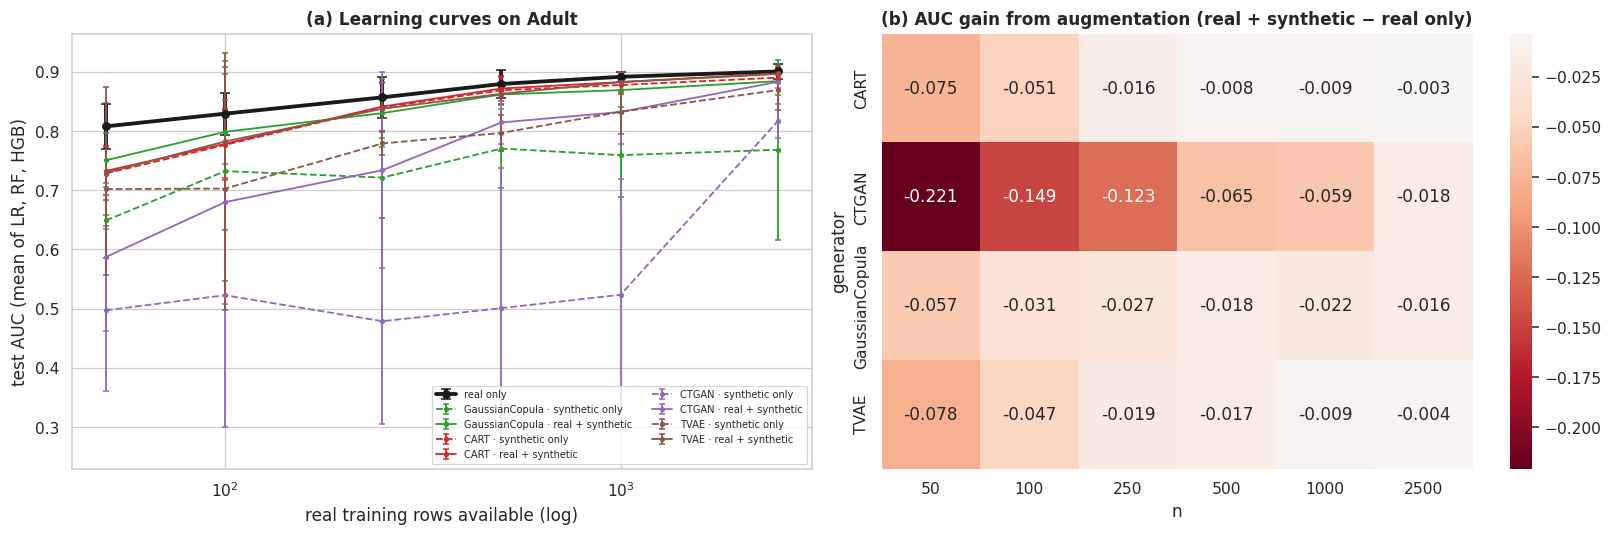

AUC gain vs real-only                                         ±95% CI                                        
n                                                50      100     250     500     1000    2500    50      100     250     500     1000    2500
generator      condition                                                                                                                     
CART           real + synthetic               -0.0753 -0.0510 -0.0155 -0.0078 -0.0089 -0.0034  0.0378  0.0554  0.0319  0.0032  0.0089  0.0049
               synthetic only                 -0.0796 -0.0528 -0.0169 -0.0107 -0.0139 -0.0104  0.0402  0.0579  0.0342  0.0006  0.0091  0.0066
CTGAN          real + synthetic               -0.2205 -0.1494 -0.1230 -0.0651 -0.0594 -0.0175  0.1505  0.1560  0.1319  0.0130  0.0496  0.0065
               synthetic only                 -0.3106 -0.3067 -0.3780 -0.3786 -0.3681 -0.0838  0.1701  0.2046  0.1477  0.2145  0.1930  0.0173
GaussianCopula real + synthetic               -0.0572 -0.0307 -0.0267 -0.0177 -0.0225 -0.0164  0.0756  0.0634  0.0640  0.0064  0.0207  0.0117
               synthetic only                 -0.1589 -0.0970 -0.1356 -0.1091 -0.1323 -0.1322  0.0369  0.1502  0.0728  0.0442  0.0662  0.1398
TVAE           real + synthetic               -0.0784 -0.0469 -0.0192 -0.0167 -0.0090 -0.0043  0.1317  0.1481  0.0313  0.0200  0.0093  0.0033
               synthetic only                 -0.1059 -0.1266 -0.0778 -0.0827 -0.0591 -0.0314  0.1074  0.2157  0.0198  0.0401  0.0312  0.0216

In [26]:
base_sc = SC[SC.condition == "real only"][["seed", "n", "auc"]].rename(columns={"auc": "auc_real"})
SCd = SC[SC.condition != "real only"].merge(base_sc, on=["seed", "n"]); SCd["gain"] = SCd.auc - SCd.auc_real
t11 = SCd.groupby(["generator", "condition", "n"]).gain.agg(["mean", ci_t]).rename(columns={"mean": "AUC gain vs real-only", "ci_t": "±95% CI"})
t11.to_csv(f"{TAB}/T11_scarcity_gain.csv")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
m = SC[SC.condition == "real only"].groupby("n").auc; axes[0].errorbar(m.mean().index, m.mean(), yerr=m.agg(ci_t), color="k", marker="o", lw=2.5, capsize=3, label="real only")
for g in SC_GENS:
    for cond, ls in [("synthetic only", "--"), ("real + synthetic", "-")]:
        s = SC[(SC.generator == g) & (SC.condition == cond)].groupby("n").auc
        axes[0].errorbar(s.mean().index, s.mean(), yerr=s.agg(ci_t), color=PALETTE[g], ls=ls, marker=".", capsize=2, label=f"{g} · {cond}")
axes[0].set_xscale("log"); axes[0].set_xlabel("real training rows available (log)"); axes[0].set_ylabel("test AUC (mean of LR, RF, HGB)")
axes[0].set_title("(a) Learning curves on Adult"); axes[0].legend(fontsize=6.5, ncol=2)
sns.heatmap(SCd[SCd.condition == "real + synthetic"].pivot_table(index="generator", columns="n", values="gain"), annot=True, fmt="+.3f", cmap="RdBu", center=0, ax=axes[1])
axes[1].set_title("(b) AUC gain from augmentation (real + synthetic − real only)")
plt.tight_layout(); savefig(fig, "F11_scarcity")
t11.unstack("n").round(4)

## 13. Experiment E6 — rare-event expansion for fraud detection (claim C10)
The paper reports "3× expansion of training datasets" for rare events. Here the fraud class (≈ 5% of training rows, ≈ 200 frauds) is expanded ×3 and ×10 with: random oversampling, SMOTE (the standard non-generative baseline) and generators fitted **on the fraud rows only**. Metric: area under the precision–recall curve (AUPRC), the right metric for rare events; 5 seeds × 2 models.

seed 0 done


seed 1 done


seed 2 done


seed 3 done


seed 4 done


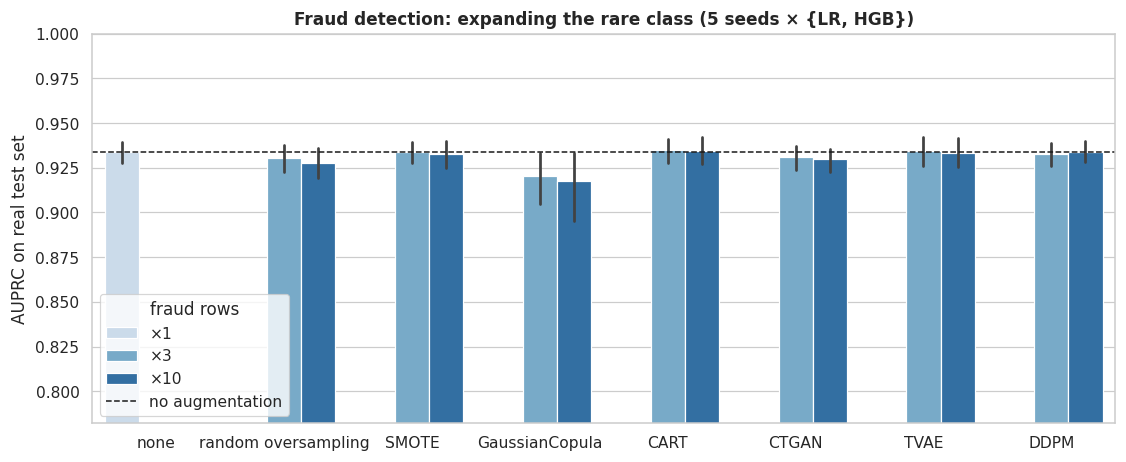

AUPRC  gain_vs_none  gain_ci  p_gain  diff_vs_SMOTE  diff_vs_SMOTE_ci
condition           mult                                                                        
CART                3     0.9347    9.1226e-04   0.0036  0.3125     6.8609e-04            0.0042
                    10    0.9346    8.5329e-04   0.0058  0.3477     1.9440e-03            0.0058
CTGAN               3     0.9308   -2.9676e-03   0.0026  0.9863    -3.1937e-03            0.0041
                    10    0.9298   -4.0026e-03   0.0029  0.9932    -2.9118e-03            0.0054
DDPM                3     0.9327   -1.1048e-03   0.0037  0.7217    -1.3310e-03            0.0036
                    10    0.9337   -9.8351e-05   0.0041  0.6152     9.9236e-04            0.0049
GaussianCopula      3     0.9203   -1.3491e-02   0.0165  0.9932    -1.3717e-02            0.0162
                    10    0.9174   -1.6363e-02   0.0223  0.9971    -1.5273e-02            0.0200
SMOTE               3     0.9340    2.2618e-04   0.0026  0.5391     0.0000e+00            0.0000
                    10    0.9327   -1.0907e-03   0.0038  0.7539     0.0000e+00            0.0000
TVAE                3     0.9341    3.2371e-04   0.0047  0.3848     9.7530e-05            0.0048
                    10    0.9331   -7.1102e-04   0.0052  0.6152     3.7970e-04            0.0066
random oversampling 3     0.9304   -3.3834e-03   0.0040  0.9473    -3.6096e-03            0.0036
                    10    0.9277   -6.0913e-03   0.0065  0.9756    -5.0005e-03            0.0038

In [27]:
from imblearn.over_sampling import SMOTE
df_fr, meta_fr = DATA["fraud"]; rare_rows = []
RARE_SEEDS = [0, 1, 2, 3, 4] if not QUICK else [0]
for seed in RARE_SEEDS:
    tr, _, te = make_split("fraud", seed); yt = (te.Class == "fraud").astype(int).values
    fr = tr[tr.Class == "fraud"].reset_index(drop=True); nf = len(fr)
    for mult in [3, 10]:
        extra = (mult - 1) * nf; sets = {"none": tr}
        sets["random oversampling"] = pd.concat([tr, fr.sample(extra, replace=True, random_state=seed)], ignore_index=True)
        X = tr.drop(columns="Class").values; y = (tr.Class == "fraud").astype(int).values
        Xs, ys = SMOTE(sampling_strategy={1: nf * mult}, random_state=seed).fit_resample(X, y)
        sets["SMOTE"] = pd.DataFrame(Xs, columns=tr.columns[:-1]).assign(Class=np.where(ys == 1, "fraud", "normal"))
        for g, fn in [("GaussianCopula", gen_gc), ("CART", gen_cart), ("CTGAN", gen_ctgan), ("TVAE", gen_tvae), ("DDPM", gen_ddpm)]:
            set_seed(seed); s = _postprocess(fn(fr, meta_fr, seed, n=extra), fr, meta_fr); s["Class"] = "fraud"
            sets[g] = pd.concat([tr, s], ignore_index=True)
        for cond, d in sets.items():
            if cond == "none" and mult == 10: continue
            for mdl in ["LR", "HGB"]:
                p = fit_predict(d, te, meta_fr, mdl, seed)
                rare_rows.append(dict(seed=seed, mult=mult if cond != "none" else 1, condition=cond, model=mdl,
                                      auprc=average_precision_score(yt, p), auc=roc_auc_score(yt, p)))
    print(f"seed {seed} done", flush=True)
RA = pd.DataFrame(rare_rows); RA.to_csv(f"{TAB}/E6_rare_events.csv", index=False)
none = RA[RA.condition == "none"][["seed", "model", "auprc"]].rename(columns={"auprc": "auprc_none"})
RAd = RA[RA.condition != "none"].merge(none, on=["seed", "model"]); RAd["gain"] = RAd.auprc - RAd.auprc_none
smote = RA[RA.condition == "SMOTE"][["seed", "model", "mult", "auprc"]].rename(columns={"auprc": "auprc_smote"})
RAd = RAd.merge(smote, on=["seed", "model", "mult"], how="left"); RAd["vs_smote"] = RAd.auprc - RAd.auprc_smote
t12 = RAd.groupby(["condition", "mult"]).agg(AUPRC=("auprc", "mean"), gain_vs_none=("gain", "mean"), gain_ci=("gain", ci_t),
      p_gain=("gain", lambda x: stats.wilcoxon(x, alternative="greater").pvalue if (x != 0).any() else np.nan),
      diff_vs_SMOTE=("vs_smote", "mean"), diff_vs_SMOTE_ci=("vs_smote", ci_t))
t12.to_csv(f"{TAB}/T12_rare_events.csv")
fig, ax = plt.subplots(figsize=(12, 4.6))
order = ["none", "random oversampling", "SMOTE", "GaussianCopula", "CART", "CTGAN", "TVAE", "DDPM"]
sns.barplot(data=RA.assign(exp=RA["mult"].map({1: "×1", 3: "×3", 10: "×10"})), x="condition", y="auprc", hue="exp", order=order, ax=ax, errorbar=("ci", 95), palette="Blues")
ax.axhline(RA[RA.condition == "none"].auprc.mean(), c="k", ls="--", lw=1, label="no augmentation")
ax.set_ylabel("AUPRC on real test set"); ax.set_xlabel(""); ax.set_title("Fraud detection: expanding the rare class (5 seeds × {LR, HGB})"); ax.legend(title="fraud rows")
ax.set_ylim(RA.auprc.min() - 0.05, 1.0); savefig(fig, "F12_rare_events"); t12

## 14. Experiment E7 — synthetic data vs. classic k-anonymity (claim C12)
Mondrian k-anonymity with k ∈ {2, 5, 10, 25, 50, 100} on Adult (3 seeds), evaluated on the same utility, membership-inference and Anonymeter linkability axes as the generators.

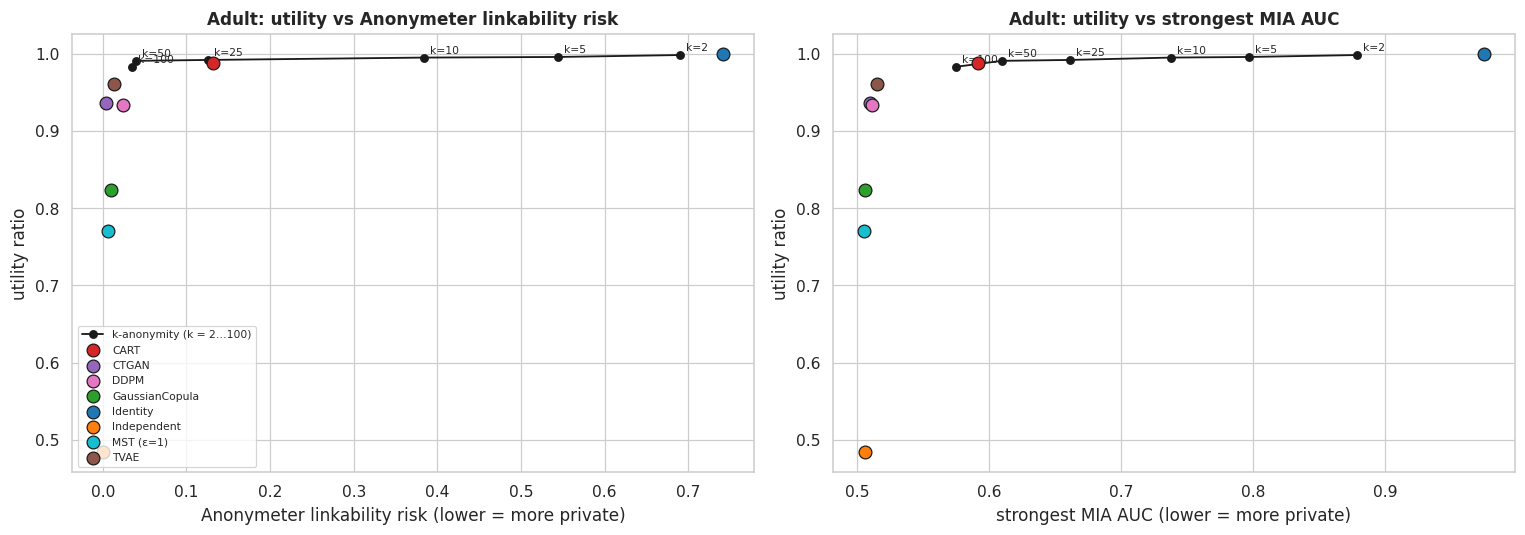

,util_ratio,mia_auc_max,mia_tpr1_max,anon_link,anon_singling,anon_infer,dcr_share
k,,,,,,,
2,0.9981,0.8791,0.1458,0.6905,0.5030,0.8941,0.9527
5,0.9956,0.7973,0.1130,0.5444,0.3912,0.8021,0.9066
10,0.9948,0.7380,0.0818,0.3842,0.3727,0.7392,0.8590
25,0.9917,0.6611,0.0469,0.1253,0.3773,0.6239,0.7837
50,0.9905,0.6097,0.0361,0.0395,0.4488,0.5374,0.7126
100,0.9828,0.5749,0.0283,0.0352,0.4848,0.5321,0.6553


Synthetic generators that dominate k-anonymity (utility ≥, linkability ≤, MIA AUC ≤):


'none'

In [28]:
ka_rows = []
for seed in DATA["adult"][1]["seeds"]:
    tr, ho, te = make_split("adult", seed); enc = Encoder(tr, meta_ad)
    u_real, _ = utility(tr, te, meta_ad, seed)
    for k in ([2, 5, 10, 25, 50, 100] if not QUICK else [10]):
        syn = _postprocess(gen_kanon(tr, meta_ad, seed, k=k), tr, meta_ad)
        u, _ = utility(syn, te, meta_ad, seed); pv = privacy(tr, ho, te, syn, meta_ad, enc, seed, anonymeter_on=True); pv.pop("_scores")
        ka_rows.append(dict(seed=seed, k=k, util_ratio=u["auc_mean"] / u_real["auc_mean"], mia_auc_max=pv["mia_auc_max"], mia_tpr1_max=pv["mia_tpr1_max"],
                            anon_link=pv["anon_link"], anon_singling=pv["anon_singling"], anon_infer=pv["anon_infer"], dcr_share=pv["dcr_share"]))
KA = pd.DataFrame(ka_rows); KA.to_csv(f"{TAB}/E7_kanon_sweep.csv", index=False)
kag = KA.groupby("k").mean().drop(columns="seed"); ad = G[G.dataset == "Adult"].groupby("generator")[["util_ratio", "anon_link", "mia_auc_max", "mia_tpr1_max", "anon_singling"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, risk, lab in [(axes[0], "anon_link", "Anonymeter linkability risk"), (axes[1], "mia_auc_max", "strongest MIA AUC")]:
    ax.plot(kag[risk], kag.util_ratio, "k-o", label="k-anonymity (k = 2…100)")
    for k, r in kag.iterrows(): ax.annotate(f"k={k}", (r[risk], r.util_ratio), fontsize=7, xytext=(4, 3), textcoords="offset points")
    for g, r in ad.iterrows():
        if g in ("k-anon (k=10)",): continue
        ax.scatter(r[risk], r.util_ratio, color=PALETTE[g], s=70, label=g, edgecolor="k", zorder=3)
    ax.set_xlabel(lab + " (lower = more private)"); ax.set_ylabel("utility ratio"); ax.set_title(f"Adult: utility vs {lab}")
axes[0].legend(fontsize=7, loc="lower left"); plt.tight_layout(); savefig(fig, "F13_kanon_vs_synthetic")
dom = []
for g, r in ad.iterrows():
    if FAMILY.get(g) in ("reference", "anonymisation"): continue
    for k, q in kag.iterrows():
        if r.util_ratio >= q.util_ratio and r.anon_link <= q.anon_link and r.mia_auc_max <= q.mia_auc_max:
            dom.append(dict(generator=g, dominates_k=k))
DOM = pd.DataFrame(dom, columns=["generator", "dominates_k"])
display(kag.round(4)); print("Synthetic generators that dominate k-anonymity (utility ≥, linkability ≤, MIA AUC ≤):")
DOM.groupby("generator").dominates_k.apply(list) if len(DOM) else "none"

## 15. Do the metrics agree? Fidelity–privacy trade-off (claim C5) and metric redundancy
Spearman correlations between all quality metrics across every synthetic run (Identity and k-anonymity excluded, since they are not generators). To stop dataset differences from creating spurious correlations, each metric is **rank-transformed within dataset** before pooling.

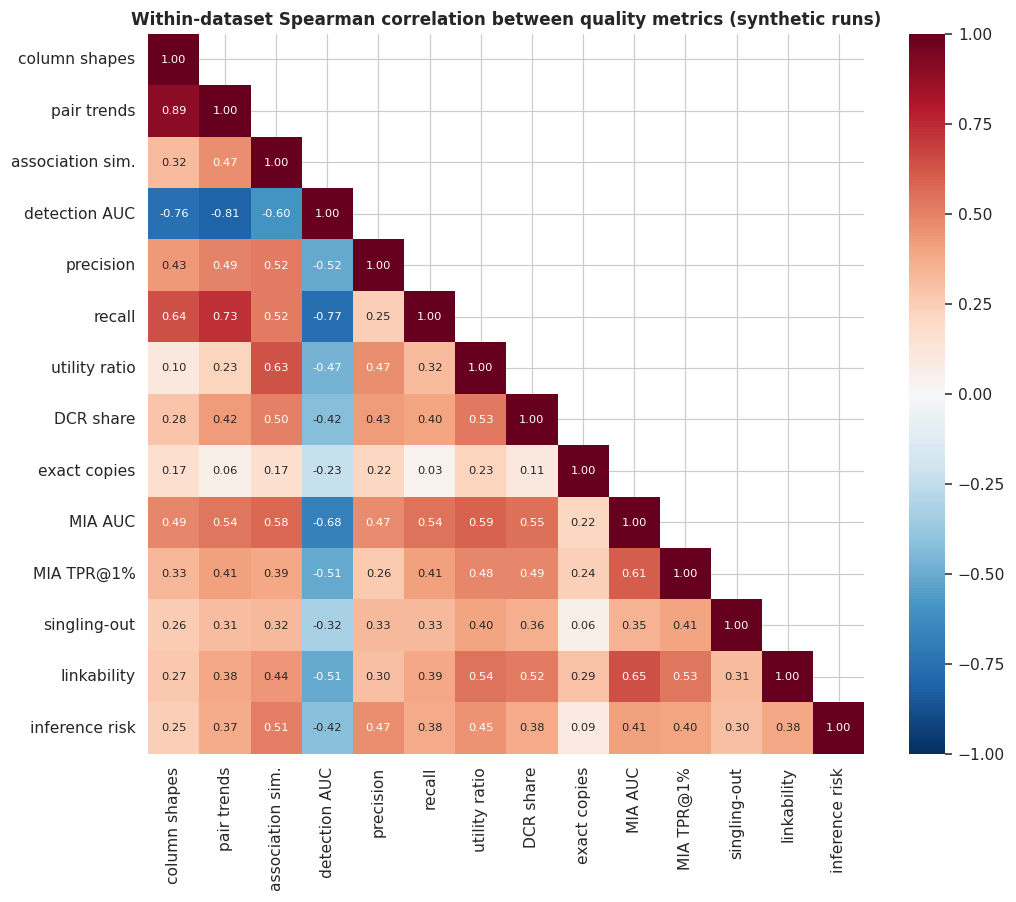

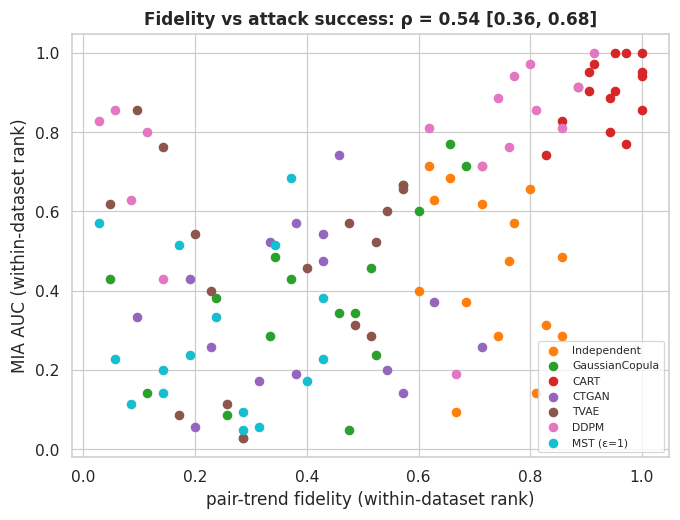

,fidelity,privacy_risk,rho,lo,hi
0,pair trends,MIA AUC,0.5364,0.3595,0.6842
1,pair trends,MIA TPR@1%,0.4096,0.2232,0.5789
2,pair trends,DCR share,0.4237,0.2258,0.5974
3,pair trends,linkability,0.3849,0.1886,0.5569
4,pair trends,MIA AUC [Adult only],0.1805,-0.3688,0.6264
5,pair trends,MIA AUC [German only],0.3081,-0.0917,0.6409
6,pair trends,MIA AUC [Fraud only],0.8013,0.4672,0.9660
7,pair trends,MIA AUC [Pima only],0.8207,0.6344,0.9062
8,association sim.,MIA AUC,0.5765,0.4226,0.7107
9,association sim.,MIA TPR@1%,0.3856,0.2007,0.5531


In [29]:
MET = {"shape": "column shapes", "pair": "pair trends", "assoc_sim": "association sim.", "detect_auc": "detection AUC", "precision": "precision",
       "recall": "recall", "util_ratio": "utility ratio", "dcr_share": "DCR share", "exact_match_syn": "exact copies", "mia_auc_max": "MIA AUC",
       "mia_tpr1_max": "MIA TPR@1%", "anon_singling": "singling-out", "anon_link": "linkability", "anon_infer": "inference risk"}
GS = G[~G.generator.isin(["Identity", "k-anon (k=10)"])].copy()
RK = GS.groupby("dataset")[list(MET)].rank(pct=True)
corr = RK.corr(method="spearman").rename(index=MET, columns=MET)
corr.to_csv(f"{TAB}/T13_metric_correlations.csv")
fig, ax = plt.subplots(figsize=(10.5, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 7.5}, mask=np.triu(np.ones_like(corr, bool), 1))
ax.set_title("Within-dataset Spearman correlation between quality metrics (synthetic runs)"); savefig(fig, "F14_metric_correlations")

def boot_spearman(x, y, B=5000, seed=0):
    rs = np.random.RandomState(seed); x, y = np.asarray(x), np.asarray(y); r0 = stats.spearmanr(x, y)[0]
    bs = [stats.spearmanr(x[i], y[i])[0] for i in (rs.randint(0, len(x), len(x)) for _ in range(B))]
    return r0, np.nanpercentile(bs, 2.5), np.nanpercentile(bs, 97.5)
c5 = []
for fid_m in ["pair", "assoc_sim", "shape"]:
    for prv in ["mia_auc_max", "mia_tpr1_max", "dcr_share", "anon_link"]:
        r, lo, hi = boot_spearman(RK[fid_m], RK[prv]); c5.append(dict(fidelity=MET[fid_m], privacy_risk=MET[prv], rho=r, lo=lo, hi=hi))
    for dname in DS_ORDER:
        s = GS[GS.dataset == dname]; r, lo, hi = boot_spearman(s[fid_m], s["mia_auc_max"])
        c5.append(dict(fidelity=MET[fid_m], privacy_risk=f"MIA AUC [{dname} only]", rho=r, lo=lo, hi=hi))
C5 = pd.DataFrame(c5); C5.to_csv(f"{TAB}/T13b_C5_tradeoff.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 5))
for g in [x for x in GEN_ORDER if x in GS.generator.unique()]:
    s = GS[GS.generator == g]; ax.scatter(RK.loc[s.index, "pair"], RK.loc[s.index, "mia_auc_max"], color=PALETTE[g], label=g, s=30)
r = C5.query("fidelity=='pair trends' and privacy_risk=='MIA AUC'").iloc[0]
ax.set_xlabel("pair-trend fidelity (within-dataset rank)"); ax.set_ylabel("MIA AUC (within-dataset rank)")
ax.set_title(f"Fidelity vs attack success: ρ = {r.rho:.2f} [{r.lo:.2f}, {r.hi:.2f}]"); ax.legend(fontsize=7); savefig(fig, "F15_fidelity_privacy")
C5

## 16. Audit of the SDSAF Pillar-3 acceptance gates (paper Table 6; claim C11)
Each gate is applied to every run exactly as the paper states it, with the closest measurable operationalisation:

| Paper gate | Operationalisation here |
|---|---|
| Fidelity: correlation > 0.90 | association similarity > 0.90 |
| Privacy: re-identification risk < 0.1% | exact-copy rate < 0.1% **and** DCR share ≤ 0.55 (vendor-style test) |
| Utility: within 5–10% of real | TSTR/TRTR ≥ 0.90 |
| Diversity: no single mode > 30% | largest k-means mode share ≤ 0.30 |
| Fairness: max 5% inter-group disparity | equalized-odds difference ≤ 0.05 for every protected attribute |

The question is whether a run that **passes** the paper's privacy + fidelity + utility gates is actually safe against membership inference.

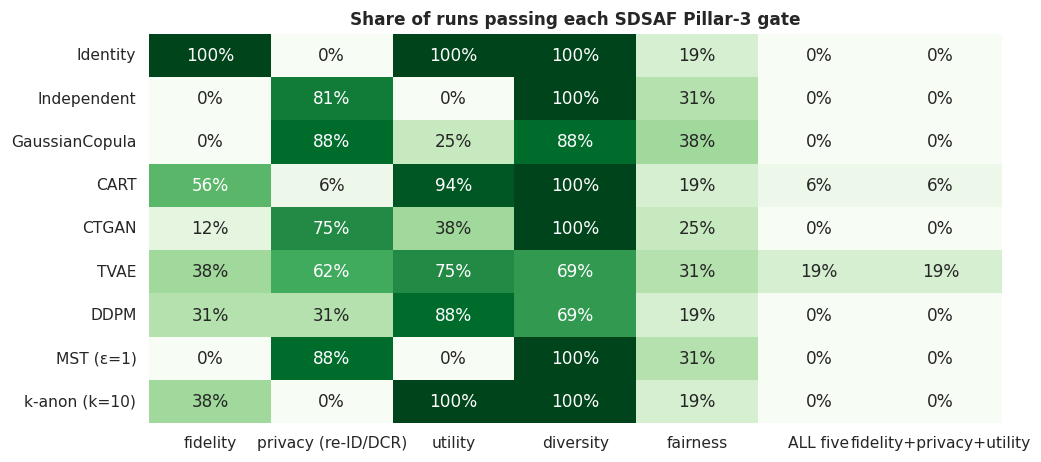

{
 "runs_total": 144,
 "runs_passing_fpu": 4,
 "of_which_attack_TPR1_ge_5pct": 0,
 "of_which_anonymeter_CI_above_0": 0,
 "share_passing_but_attackable": 0.0
}


,dataset,seed,generator,assoc_sim,dcr_share,exact_match_syn,util_ratio,mia_auc_max,mia_tpr1_max,anon_singling,anon_link,anon_infer
104,Fraud,2,CART,0.9820,0.5475,0.0,0.9855,0.5567,0.0222,0.0276,0.0184,0.3096
86,Fraud,0,TVAE,0.9358,0.5270,0.0,0.9906,0.5154,0.0168,0.0418,0.0000,0.0000
106,Fraud,2,TVAE,0.9458,0.5174,0.0,0.9806,0.5169,0.0138,0.0326,0.0000,0.2747
96,Fraud,1,TVAE,0.9417,0.5209,0.0,0.9857,0.5129,0.0135,0.0362,0.0207,0.2525


,fidelity,privacy (re-ID/DCR),utility,diversity,fairness,ALL five,fidelity+privacy+utility
generator,,,,,,,
Identity,1.0000,0.0000,1.0000,1.0000,0.1875,0.0000,0.0000
Independent,0.0000,0.8125,0.0000,1.0000,0.3125,0.0000,0.0000
GaussianCopula,0.0000,0.8750,0.2500,0.8750,0.3750,0.0000,0.0000
CART,0.5625,0.0625,0.9375,1.0000,0.1875,0.0625,0.0625
CTGAN,0.1250,0.7500,0.3750,1.0000,0.2500,0.0000,0.0000
TVAE,0.3750,0.6250,0.7500,0.6875,0.3125,0.1875,0.1875
DDPM,0.3125,0.3125,0.8750,0.6875,0.1875,0.0000,0.0000
MST (ε=1),0.0000,0.8750,0.0000,1.0000,0.3125,0.0000,0.0000
k-anon (k=10),0.3750,0.0000,1.0000,1.0000,0.1875,0.0000,0.0000


In [30]:
AU = G.copy()
AU["gate_fidelity"] = AU.assoc_sim > 0.90
AU["gate_privacy"] = (AU.exact_match_syn < 0.001) & (AU.dcr_share <= 0.55)
AU["gate_utility"] = AU.util_ratio >= 0.90
AU["gate_diversity"] = AU.max_mode_syn <= 0.30
eo_cols = [c for c in AU.columns if c.endswith("|eo_diff") and "real" not in c]
AU["gate_fairness"] = AU[eo_cols].max(axis=1, skipna=True).le(0.05) | AU[eo_cols].isna().all(axis=1)
gates = ["gate_fidelity", "gate_privacy", "gate_utility", "gate_diversity", "gate_fairness"]
AU["passes_all"] = AU[gates].all(axis=1); AU["passes_fpu"] = AU[["gate_fidelity", "gate_privacy", "gate_utility"]].all(axis=1)
AU["attack_succeeds"] = AU.mia_tpr1_max >= 0.05
AU["anon_detects"] = (AU[["anon_singling_lo", "anon_link_lo", "anon_infer_lo"]] > 0).any(axis=1)
pr = AU.groupby("generator")[gates + ["passes_all", "passes_fpu"]].mean().reindex(GEN_ORDER)
pr.columns = ["fidelity", "privacy (re-ID/DCR)", "utility", "diversity", "fairness", "ALL five", "fidelity+privacy+utility"]
pr.to_csv(f"{TAB}/T14_sdsaf_gate_pass_rates.csv")
fig, ax = plt.subplots(figsize=(10, 4.6))
sns.heatmap(pr, annot=True, fmt=".0%", cmap="Greens", vmin=0, vmax=1, ax=ax, cbar=False); ax.set_title("Share of runs passing each SDSAF Pillar-3 gate"); ax.set_ylabel("")
savefig(fig, "F16_sdsaf_gates")
passed = AU[AU.passes_fpu & ~AU.generator.isin(["Identity"])]
c11 = dict(runs_total=len(AU), runs_passing_fpu=len(passed), of_which_attack_TPR1_ge_5pct=int(passed.attack_succeeds.sum()),
           of_which_anonymeter_CI_above_0=int(passed.anon_detects.sum()),
           share_passing_but_attackable=(passed.attack_succeeds.mean() if len(passed) else np.nan))
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in c11.items()}, indent=1))
display(passed[["dataset", "seed", "generator", "assoc_sim", "dcr_share", "exact_match_syn", "util_ratio", "mia_auc_max", "mia_tpr1_max", "anon_singling", "anon_link", "anon_infer"]]
        .sort_values("mia_tpr1_max", ascending=False).head(15))
pr

### Data-driven gates
If the paper's thresholds are to stay, what thresholds does the evidence support? For each run we mark it "unsafe" if the strongest attack reaches TPR@1%FPR ≥ 5% or any Anonymeter risk CI excludes zero, and ask which single metric threshold best separates safe from unsafe runs.

In [31]:
AU["unsafe"] = AU.attack_succeeds | AU.anon_detects
cand = {"DCR share": "dcr_share", "exact copies": "exact_match_syn", "association sim.": "assoc_sim", "pair trends": "pair", "detection AUC": "detect_auc", "utility ratio": "util_ratio"}
sep = []
for lab, c in cand.items():
    x = AU[c].values; y = AU.unsafe.astype(int).values
    if len(np.unique(y)) < 2: break
    auc = roc_auc_score(y, x); sep.append(dict(metric=lab, AUC_for_flagging_unsafe=max(auc, 1 - auc), direction="higher = riskier" if auc >= 0.5 else "lower = riskier"))
SEP = pd.DataFrame(sep).sort_values("AUC_for_flagging_unsafe", ascending=False) if sep else pd.DataFrame()
SEP.to_csv(f"{TAB}/T15_gate_separability.csv", index=False)
print(f"Unsafe runs: {AU.unsafe.sum()} / {len(AU)}"); SEP

Unsafe runs: 72 / 144


,metric,AUC_for_flagging_unsafe,direction
0,DCR share,0.8517,higher = riskier
5,utility ratio,0.8266,higher = riskier
2,association sim.,0.7969,higher = riskier
4,detection AUC,0.7660,lower = riskier
3,pair trends,0.7542,higher = riskier
1,exact copies,0.6982,higher = riskier


## 17. Verdicts on the manuscript's claims
The decision rules from Section 2 are applied mechanically to the results above.

In [32]:
SYN6 = ["GaussianCopula", "CART", "CTGAN", "TVAE", "DDPM", "MST (ε=1)"]
V = []
def verdict(cid, claim, v, evidence): V.append(dict(ID=cid, claim=claim, verdict=v, evidence=evidence))

# C1
sig = tests[tests.generator.isin(MAINSTREAM) & tests.significant]
anon_rate = G[G.generator.isin(MAINSTREAM)].groupby("generator").apply(lambda s: (s[["anon_singling_lo", "anon_link_lo", "anon_infer_lo"]] > 0).any(axis=1).mean())
leaky = sorted(set(sig.generator) | set(anon_rate[anon_rate > 0.05].index))
best = G[G.generator.isin(MAINSTREAM)].groupby("generator")[["mia_auc_max", "mia_tpr1_max"]].mean()
verdict("C1", "Synthetic data cannot be traced to individuals", "Refuted" if leaky else "Not refuted (in these tests)",
        (f"Significant membership leakage for: {', '.join(leaky)}. " if leaky else "No generator leaked significantly. ") +
        f"Highest mean attack AUC {best.mia_auc_max.max():.3f} ({best.mia_auc_max.idxmax()}); highest mean TPR@1%FPR {best.mia_tpr1_max.max():.3f} ({best.mia_tpr1_max.idxmax()}; chance = 0.010).")
# C2 / C3
for cid, thr, txt in [("C2", 0.90, "within 5–10% of real data (abstract)"), ("C3", 0.95, "within 2–5% for most tasks (conclusion)")]:
    meet = [g for g in SYN6 if pooled[g][1] >= thr]
    v = "Supported" if len(meet) > len(SYN6) / 2 else ("Partially supported" if meet else "Not supported")
    verdict(cid, f"Utility {txt}", v, f"{len(meet)}/{len(SYN6)} generators meet it ({', '.join(meet) or 'none'}). Pooled ratios: " +
            "; ".join(f"{g} {pooled[g][0]:.3f}" for g in SYN6))
# C4
t8h = t8.reindex(SYN6).copy(); t8h["p_eo_holm"] = holm(t8h["Wilcoxon p (EO syn>real)"].fillna(1))
amp = [g for g in SYN6 if t8h.loc[g, "share of runs gap amplified"] > 0.5 and t8h.loc[g, "sign-test p (gap)"] < 0.05]
eo = [g for g in SYN6 if t8h.loc[g, "p_eo_holm"] < 0.05]
either = sorted(set(amp) | set(eo))
verdict("C4", "Synthetic data can amplify bias", "Supported" if len(either) > len(SYN6) / 2 else ("Partially supported" if either else "Not supported"),
        f"Gap enlarged in most runs: {', '.join(amp) or 'none'}; equalized-odds significantly worse: {', '.join(eo) or 'none'}. "
        f"Mean representation ratio of protected groups ranges {t8h['representation ratio'].min():.2f}–{t8h['representation ratio'].max():.2f}.")
# C5
r = C5.query("fidelity=='pair trends' and privacy_risk=='MIA AUC'").iloc[0]
verdict("C5", "Higher fidelity costs privacy", "Supported" if r.lo > 0 else ("Contradicted" if r.hi < 0 else "Not supported"),
        f"Within-dataset Spearman ρ(pair-trend fidelity, MIA AUC) = {r.rho:.2f}, 95% CI [{r.lo:.2f}, {r.hi:.2f}].")
# C6
pp = stats.wilcoxon(DPL.extra_drop, alternative="greater").pvalue
verdict("C6", "Privacy constraints reduce fairness for minority groups", "Supported" if pp < 0.05 else "Not supported",
        f"Under MST across ε, protected-group AUC loss exceeds reference-group loss by {DPL.extra_drop.mean():+.3f} on average (Wilcoxon p = {pp:.3g}, n = {len(DPL)}).")
# C7 / C8
er = t9.reindex(SYN6).energy_ratio_syn_over_real
verdict("C7", "Synthetic pipelines reduce energy use by 30–60%", "Supported" if (er <= 0.70).sum() > len(SYN6) / 2 else "Not supported",
        f"Measured median energy of synthetic pipeline / real pipeline: " + "; ".join(f"{g} {v:.1f}×" for g, v in er.items()) + ". Generating data adds compute; it cannot remove the downstream training cost.")
sr = t9b.reindex(SYN6)
verdict("C8", "Synthetic data reduces storage by 40–60%", "Supported" if (sr["size ratio (gzip)"] <= 0.60).sum() > len(SYN6) / 2 else "Not supported",
        "At equal row count, compressed size ratio synthetic/real: " + "; ".join(f"{g} {v:.2f}" for g, v in sr["size ratio (gzip)"].items()) + ".")
# C9
small = SCd[(SCd.condition == "real + synthetic") & (SCd.n <= 100)].groupby("generator").gain.agg(["mean", ci_t])
helps = [g for g, q in small.iterrows() if q["mean"] - q["ci_t"] > 0]
large = SCd[(SCd.condition == "real + synthetic") & (SCd.n >= 1000)].groupby("generator").gain.mean()
verdict("C9", "Synthetic augmentation helps under data scarcity (P2)", "Supported" if len(helps) > len(small) / 2 else ("Partially supported" if helps else "Not supported"),
        "Mean AUC gain at n ≤ 100: " + "; ".join(f"{g} {q['mean']:+.3f}±{q['ci_t']:.3f}" for g, q in small.iterrows()) +
        ". At n ≥ 1,000: " + "; ".join(f"{g} {v:+.3f}" for g, v in large.items()) + ".")
# C10
t12r = t12.reset_index(); gen_rows = t12r[t12r.condition.isin(["GaussianCopula", "CART", "CTGAN", "TVAE", "DDPM"])]
good = gen_rows[(gen_rows.gain_vs_none - gen_rows.gain_ci > 0) & (gen_rows.diff_vs_SMOTE >= 0)]
verdict("C10", "Synthetic rare-event expansion improves models", "Supported" if len(good) else "Not supported",
        (f"Beneficial and ≥ SMOTE: {', '.join(f'{a} ×{b}' for a, b in zip(good.condition, good.mult))}. " if len(good) else "No generator beat both no-augmentation (CI) and SMOTE. ") +
        f"Best generator AUPRC gain {gen_rows.gain_vs_none.max():+.3f}; SMOTE ×3 gain {t12r[(t12r.condition=='SMOTE')&(t12r.mult==3)].gain_vs_none.iloc[0]:+.3f}.")
# C11
if c11["runs_passing_fpu"] == 0:
    verdict("C11", "SDSAF Table-6 gates are adequate", "Not supported", "No generator run passes the fidelity + privacy + utility gates together, so the gates cannot be met in practice with these generators.")
else:
    s = c11["share_passing_but_attackable"]
    verdict("C11", "SDSAF Table-6 gates are adequate", "Not supported" if s > 0.10 else "Supported",
            f"{c11['runs_passing_fpu']} runs pass fidelity + privacy + utility gates; {c11['of_which_attack_TPR1_ge_5pct']} of them ({s:.0%}) are still attackable at TPR@1%FPR ≥ 5%, "
            f"{c11['of_which_anonymeter_CI_above_0']} flagged by Anonymeter. ALL-five pass rate per generator: " + "; ".join(f"{g} {pr.loc[g, 'ALL five']:.0%}" for g in SYN6))
# C12
verdict("C12", "Synthetic data beats classic anonymisation", "Supported" if len(DOM) else "Not supported",
        (f"Dominating generators (utility ≥, linkability ≤, MIA AUC ≤): " + "; ".join(f"{g} (k ∈ {sorted(set(d))})" for g, d in DOM.groupby('generator').dominates_k)) if len(DOM)
        else "No synthetic generator is simultaneously more useful and less linkable than k-anonymity at any k tested.")
VERDICTS = pd.DataFrame(V); VERDICTS.to_csv(f"{TAB}/T16_verdicts.csv", index=False)
def _col(v): return {"Supported": "background-color:#d4edda", "Refuted": "background-color:#f8d7da", "Not supported": "background-color:#f8d7da",
                     "Contradicted": "background-color:#f8d7da", "Partially supported": "background-color:#fff3cd"}.get(v, "")
VERDICTS.style.map(_col, subset=["verdict"]).set_properties(subset=["evidence"], **{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index")

ID,claim,verdict,evidence
C1,Synthetic data cannot be traced to individuals,Refuted,"Significant membership leakage for: CART, CTGAN, DDPM, GaussianCopula, TVAE. Highest mean attack AUC 0.607 (CART); highest mean TPR@1%FPR 0.065 (DDPM; chance = 0.010)."
C2,Utility within 5–10% of real data (abstract),Partially supported,"2/6 generators meet it (CART, DDPM). Pooled ratios: GaussianCopula 0.849; CART 0.967; CTGAN 0.777; TVAE 0.908; DDPM 0.946; MST (ε=1) 0.745"
C3,Utility within 2–5% for most tasks (conclusion),Partially supported,1/6 generators meet it (CART). Pooled ratios: GaussianCopula 0.849; CART 0.967; CTGAN 0.777; TVAE 0.908; DDPM 0.946; MST (ε=1) 0.745
C4,Synthetic data can amplify bias,Not supported,Gap enlarged in most runs: none; equalized-odds significantly worse: none. Mean representation ratio of protected groups ranges 0.80–1.55.
C5,Higher fidelity costs privacy,Supported,"Within-dataset Spearman ρ(pair-trend fidelity, MIA AUC) = 0.54, 95% CI [0.36, 0.68]."
C6,Privacy constraints reduce fairness for minority groups,Not supported,"Under MST across ε, protected-group AUC loss exceeds reference-group loss by -0.044 on average (Wilcoxon p = 1, n = 96)."
C7,Synthetic pipelines reduce energy use by 30–60%,Not supported,Measured median energy of synthetic pipeline / real pipeline: GaussianCopula 2.1×; CART 1.1×; CTGAN 35.8×; TVAE 9.6×; DDPM 227.1×; MST (ε=1) 37.8×. Generating data adds compute; it cannot remove the downstream training cost.
C8,Synthetic data reduces storage by 40–60%,Not supported,"At equal row count, compressed size ratio synthetic/real: GaussianCopula 1.20; CART 0.97; CTGAN 1.10; TVAE 0.87; DDPM 1.15; MST (ε=1) 1.30."
C9,Synthetic augmentation helps under data scarcity (P2),Not supported,"Mean AUC gain at n ≤ 100: CART -0.063±0.023; CTGAN -0.185±0.071; GaussianCopula -0.044±0.030; TVAE -0.063±0.056. At n ≥ 1,000: CART -0.006; CTGAN -0.038; GaussianCopula -0.019; TVAE -0.007."
C10,Synthetic rare-event expansion improves models,Not supported,No generator beat both no-augmentation (CI) and SMOTE. Best generator AUPRC gain +0.001; SMOTE ×3 gain +0.000.


## 18. Headline numbers for the manuscript
Printed from the result tables so they can be copied into the paper without re-typing.

In [33]:
hl = {}
hl["real-data AUC (mean of 3 models)"] = {m["name"]: round(REAL[REAL.dataset == m["name"]].auc_mean.mean(), 3) for _, m in DATA.values()}
hl["utility ratio, pooled mean [95% CI]"] = {g: f"{pooled[g][0]:.3f} [{pooled[g][1]:.3f}, {pooled[g][2]:.3f}]" for g in GEN_ORDER}
hl["strongest MIA AUC (mean)"] = G.groupby("generator").mia_auc_max.mean().round(3).reindex(GEN_ORDER).to_dict()
hl["TPR @ 1% FPR (mean)"] = G.groupby("generator").mia_tpr1_max.mean().round(3).reindex(GEN_ORDER).to_dict()
hl["outlier vs typical-record MIA AUC"] = {g: f"{a:.3f} vs {b:.3f}" for g, (a, b) in t7[["mia_auc_outlier", "mia_auc_inlier"]].iterrows()}
hl["exact copies of training rows (mean)"] = G.groupby("generator").exact_match_syn.mean().round(4).reindex(GEN_ORDER).to_dict()
hl["generator energy (Wh, mean)"] = (1000 * G.groupby("generator").gen_kwh.mean()).round(4).reindex(GEN_ORDER).to_dict()
hl["runs"] = dict(main_benchmark=len(G), dp_sweep=len(DP), scarcity=len(SC), rare_event=len(RA), kanon_sweep=len(KA))
json.dump(hl, open(f"{TAB}/headline_numbers.json", "w"), indent=1, ensure_ascii=False)
for k, v in hl.items():
    print(f"\n{k}:"); [print(f"   {a:<22} {b}") for a, b in v.items()]


real-data AUC (mean of 3 models):
   Adult                  0.907
   German                 0.762
   Fraud                  0.988
   Pima                   0.82

utility ratio, pooled mean [95% CI]:
   Identity               1.000 [1.000, 1.000]
   Independent            0.633 [0.573, 0.690]
   GaussianCopula         0.849 [0.824, 0.874]
   CART                   0.967 [0.952, 0.982]
   CTGAN                  0.777 [0.737, 0.817]
   TVAE                   0.908 [0.878, 0.938]
   DDPM                   0.946 [0.930, 0.962]
   MST (ε=1)              0.745 [0.711, 0.777]
   k-anon (k=10)          0.992 [0.988, 0.995]

strongest MIA AUC (mean):
   Identity               0.995
   Independent            0.531
   GaussianCopula         0.521
   CART                   0.607
   CTGAN                  0.515
   TVAE                   0.524
   DDPM                   0.59
   MST (ε=1)              0.517
   k-anon (k=10)          0.847

TPR @ 1% FPR (mean):
   Identity               0.85
   Indepen

## 19. Threats to validity
* **Scope.** Four tabular datasets and nine mechanisms. Image, text and LLM-based generators were not evaluated; claims about them in the manuscript remain literature-based.
* **Hyper-parameters.** Library defaults, no tuning. Tuned generators could reach higher utility — and, because tuning raises fidelity, possibly higher leakage. DDPM is a simplified TabDDPM trained for 5,000 steps on CPU; TabDDPM itself was not run.
* **Attack strength.** The three attacks are black-box and need no shadow models. Stronger attacks (shadow-model MIAs, Stadler et al., 2022; Houssiau et al., 2022) can only increase the measured risk, so the privacy results are a *lower bound* on risk.
* **Sample sizes.** German and Pima are small (≈ 300–400 training rows). Their confidence intervals are wide; this is why they use 5 seeds.
* **Energy.** CodeCarbon estimates CPU power from rated power (no RAPL counters available), so absolute kWh are estimates; ratios between pipelines on the same machine are reliable. Data-collection energy is not measurable here.
* **Fairness thresholds.** A 0.5 decision threshold is used for demographic parity and equalized odds; other thresholds change absolute values but the synthetic-vs-real comparison uses the same threshold.
* **Fraud subsample.** All 492 frauds + 9,508 random normals (fraud rate 4.9% instead of 0.17%) to keep enough positives per split.
* **MST decoding.** MST releases binned numerics; bins are decoded uniformly within the bin range (post-processing, no privacy cost). Its structure (a maximum spanning tree of 2-way marginals) keeps only a few relationships with the label, which is the main reason for its low utility on the 20-attribute German data, independent of ε.
* **DCR share below 0.5.** On the small datasets (≈ 300–400 training rows) some generators produce DCR shares well below 0.5 (synthetic rows closer to holdout than to training rows). This is sampling noise at small n, not evidence of privacy, and the "≤ 0.55" DCR gate counts such runs as passing.

## 20. Sensitivity and exploratory analyses (added after the first full run)
**Transparency note.** The first complete run of this notebook revealed a decoding defect in the MST integration. SmartNoise's `LabelTransformer` reserves a "null" code by default, so MST emitted a literal `"None"` category in up to 9% of rows. The defect was fixed (`nullable=False`; numeric bins are now decoded uniformly within the bin), and the **entire notebook was re-executed from scratch**. Every number above comes from that corrected run.

The analyses in this section were designed **after** seeing the first run. They are sensitivity and exploratory checks: they are reported for completeness and are **not** used to change any pre-specified verdict in Section 17.

### 20.1 C1 sensitivity: a stricter test for Anonymeter
The pre-specified rule flags a generator if Anonymeter's CI lower bound is > 0 in more than 5% of runs, for *any* of three risks. With three risks per run, chance alone can exceed 5%. Here each risk is tested separately: a one-sided binomial test of the number of runs with CI > 0 against the 2.5% expected under zero risk, Holm-corrected over all generator × risk pairs.

Generators with significant membership inference (Holm): ['CART', 'DDPM', 'GaussianCopula', 'Identity', 'Independent', 'TVAE', 'k-anon (k=10)']
Generators flagged by Anonymeter under the stricter binomial test: ['CART', 'DDPM', 'Identity', 'k-anon (k=10)']


risk,infer,link,singling
runs with Anonymeter CI > 0 (of 16),,,
Identity,16,16,16
Independent,1,0,1
GaussianCopula,0,1,3
CART,4,14,9
CTGAN,1,0,1
TVAE,1,1,2
DDPM,7,7,6
MST (ε=1),1,0,2
k-anon (k=10),16,16,16


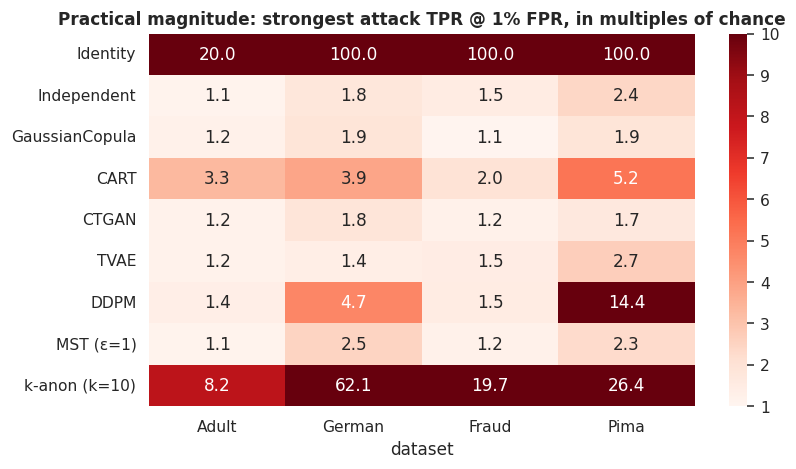

In [34]:
from scipy.stats import binomtest
s1 = []
for g in GEN_ORDER:
    s = G[G.generator == g]
    for rk in ["singling", "link", "infer"]:
        k = int((s[f"anon_{rk}_lo"] > 0).sum()); s1.append(dict(generator=g, risk=rk, runs_CI_above_0=k, runs=len(s), p=binomtest(k, len(s), 0.025, alternative="greater").pvalue))
S1 = pd.DataFrame(s1); S1["p_holm"] = holm(S1.p); S1["flagged"] = S1.p_holm < 0.05
S1.to_csv(f"{TAB}/S1_anonymeter_binomial.csv", index=False)
mia_flag = sorted(set(tests[tests.significant].generator))
anon_flag = sorted(set(S1[S1.flagged].generator))
print("Generators with significant membership inference (Holm):", mia_flag)
print("Generators flagged by Anonymeter under the stricter binomial test:", anon_flag)
display(S1.pivot(index="generator", columns="risk", values="runs_CI_above_0").reindex(GEN_ORDER).rename_axis("runs with Anonymeter CI > 0 (of 16)"))
mag = G.groupby(["generator", "dataset"]).agg(auc=("mia_auc_max", "mean"), tpr1=("mia_tpr1_max", "mean")).reset_index()
mag["x_chance"] = mag.tpr1 / 0.01
MAG = mag.pivot(index="generator", columns="dataset", values="x_chance").reindex(GEN_ORDER)[DS_ORDER]
MAG.to_csv(f"{TAB}/S1b_attack_times_chance.csv")
fig, ax = plt.subplots(figsize=(8, 4.4))
sns.heatmap(MAG, annot=True, fmt=".1f", cmap="Reds", vmin=1, vmax=10, ax=ax); ax.set_title("Practical magnitude: strongest attack TPR @ 1% FPR, in multiples of chance"); ax.set_ylabel("")
savefig(fig, "S1_attack_magnitude")

### 20.2 C4 exploratory: do generators erase or inflate protected groups?
The pre-specified C4 rule looks at outcome gaps and equalized odds. Figure 8(c) suggested a different failure: some generators change **how many** protected-group members exist at all. A run counts as *collapsed* if the group's share in the synthetic data is below half its real share, and *inflated* if it is above 1.5×.

Generator × attribute combinations where the protected group collapsed or inflated in most runs:


real_share  synthetic_share  min_ratio  max_ratio  runs_collapsed  runs_inflated  runs
generator attr                                                                                                  
CTGAN     Adult:race           0.140            0.236      1.133      2.270               0              2     3
DDPM      German:age<=25       0.188            0.322      1.466      2.184               0              4     5
          German:sex           0.318            0.726      2.078      2.573               0              5     5
TVAE      Adult:race           0.140            0.009      0.032      0.114               3              0     3
          German:sex           0.318            0.050      0.016      0.296               5              0     5

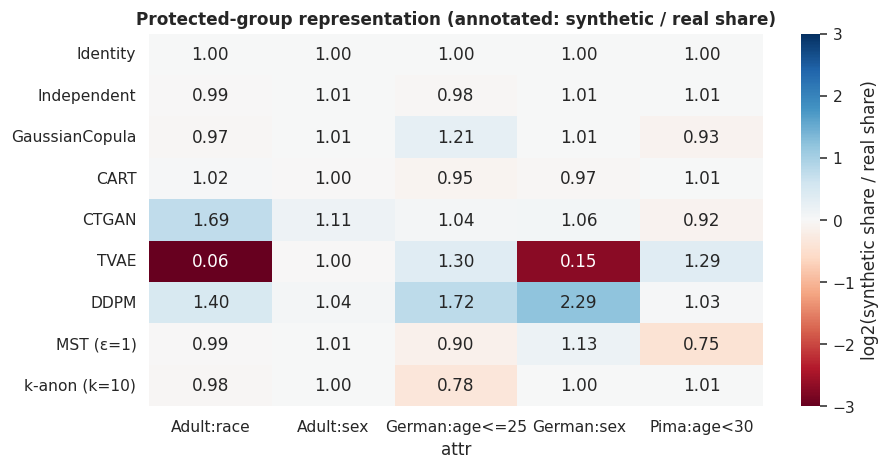

In [35]:
rep = FR.groupby(["generator", "attr"]).agg(real_share=("share_real", "mean"), synthetic_share=("share_syn", "mean"),
        min_ratio=("repr_ratio", "min"), max_ratio=("repr_ratio", "max"),
        runs_collapsed=("repr_ratio", lambda x: int((x < 0.5).sum())), runs_inflated=("repr_ratio", lambda x: int((x > 1.5).sum())), runs=("repr_ratio", "size"))
rep.to_csv(f"{TAB}/S2_representation.csv")
flagged = rep[(rep.runs_collapsed > rep.runs / 2) | (rep.runs_inflated > rep.runs / 2)]
print("Generator × attribute combinations where the protected group collapsed or inflated in most runs:")
display(flagged.round(3))
fig, ax = plt.subplots(figsize=(9, 4.4))
sns.heatmap(np.log2(FR.groupby(["generator", "attr"]).repr_ratio.mean().unstack().reindex(GEN_ORDER)), annot=FR.groupby(["generator", "attr"]).repr_ratio.mean().unstack().reindex(GEN_ORDER),
            fmt=".2f", cmap="RdBu", center=0, vmin=-3, vmax=3, ax=ax, cbar_kws={"label": "log2(synthetic share / real share)"})
ax.set_title("Protected-group representation (annotated: synthetic / real share)"); ax.set_ylabel(""); savefig(fig, "S2_representation")

### 20.3 C11 nuance: the privacy gate on its own
C11 was judged on runs passing fidelity + privacy + utility together. Because few runs pass all three, here is the privacy gate (exact copies < 0.1% and DCR share ≤ 0.55) on its own. This is the check a practitioner would rely on for a "privacy sign-off".

In [36]:
pg = AU[AU.gate_privacy & ~AU.generator.isin(["Identity"])]
s3 = dict(runs_passing_privacy_gate=len(pg), attackable_TPR1_ge_5pct=int(pg.attack_succeeds.sum()), anonymeter_CI_above_0=int(pg.anon_detects.sum()),
          either=int(pg.unsafe.sum()), share_unsafe=round(float(pg.unsafe.mean()), 3) if len(pg) else np.nan,
          runs_passing_all_five_gates=int(AU.passes_all.sum()), of_synthetic_runs=int((~AU.generator.isin(["Identity", "k-anon (k=10)"])).sum()))
print(json.dumps(s3, indent=1)); pd.Series(s3).to_csv(f"{TAB}/S3_privacy_gate_alone.csv")
pg[pg.unsafe][["dataset", "seed", "generator", "dcr_share", "exact_match_syn", "mia_tpr1_max", "anon_singling", "anon_link", "anon_infer"]].sort_values("mia_tpr1_max", ascending=False).round(3)

{
 "runs_passing_privacy_gate": 69,
 "attackable_TPR1_ge_5pct": 3,
 "anonymeter_CI_above_0": 12,
 "either": 12,
 "share_unsafe": 0.174,
 "runs_passing_all_five_gates": 4,
 "of_synthetic_runs": 112
}


,dataset,seed,generator,dcr_share,exact_match_syn,mia_tpr1_max,anon_singling,anon_link,anon_infer
67,German,3,DDPM,0.405,0.0,0.060,0.055,0.230,0.073
116,Pima,0,TVAE,0.521,0.0,0.059,0.013,0.154,0.104
37,German,0,DDPM,0.322,0.0,0.052,0.000,0.097,0.209
132,Pima,2,Independent,0.524,0.0,0.039,0.033,0.022,0.185
68,German,3,MST (ε=1),0.518,0.0,0.028,0.060,0.000,0.086
53,German,2,GaussianCopula,0.495,0.0,0.018,0.103,0.000,0.000
97,Fraud,1,DDPM,0.518,0.0,0.016,0.054,0.000,0.406
107,Fraud,2,DDPM,0.549,0.0,0.015,0.000,0.000,0.503
3,Adult,0,GaussianCopula,0.515,0.0,0.014,0.006,0.028,0.007
66,German,3,TVAE,0.335,0.0,0.012,0.073,0.000,0.000


In [37]:
elapsed = (time.time() - T_START) / 60
print(f"Notebook finished {datetime.datetime.now().isoformat(timespec='seconds')} — total runtime {elapsed:.1f} min ({elapsed/60:.2f} h)")
print("Tables written:", sorted(os.listdir(TAB)))
print("Figures written:", sorted(os.listdir(FIG)))

Notebook finished 2026-09-27T13:35:47 — total runtime 155.2 min (2.59 h)
Tables written: ['E3_dp_sweep.csv', 'E5_scarcity.csv', 'E6_rare_events.csv', 'E7_kanon_sweep.csv', 'S1_anonymeter_binomial.csv', 'S1b_attack_times_chance.csv', 'S2_representation.csv', 'S3_privacy_gate_alone.csv', 'T0_datasets.csv', 'T10_dp_fairness.csv', 'T11_scarcity_gain.csv', 'T12_rare_events.csv', 'T13_metric_correlations.csv', 'T13b_C5_tradeoff.csv', 'T14_sdsaf_gate_pass_rates.csv', 'T15_gate_separability.csv', 'T16_verdicts.csv', 'T1_metric_validation.csv', 'T2_real_baseline.csv', 'T3_utility_ratio.csv', 'T3b_utility_by_model.csv', 'T4_fidelity_diversity.csv', 'T5_privacy_pooled.csv', 'T6_C1_mia_tests.csv', 'T6b_C1_anonymeter.csv', 'T7_outlier_vulnerability.csv', 'T8_fairness.csv', 'T9_energy.csv', 'T9b_storage.csv', 'fairness_long.csv', 'headline_numbers.json', 'main_results.csv']
Figures written: ['F10_dp_frontier.png', 'F11_scarcity.png', 'F12_rare_events.png', 'F13_kanon_vs_synthetic.png', 'F14_metric_c